<a href="https://www.kaggle.com/code/lalit7881/indian-telecom-eda?scriptVersionId=365475030" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lalit7881/indian-telecom-dataset/IndiaTelecomData.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/lalit7881/indian-telecom-dataset/IndiaTelecomData.csv")

In [3]:
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020/1/1,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020/1/1,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020/1/1,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020/1/1,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020/1/1,2,55098,78,15,1393,0


In [4]:
df.tail()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
2021,2022,Reliance Jio,M,33,West Bengal,Hyderabad,432870,2020/1/11,1,53651,61,-3,1950,1
2022,2023,Airtel,M,74,Bihar,Chennai,275328,2020/1/11,0,126393,55,28,2708,1
2023,2024,Vodafone,F,20,Tripura,Delhi,720926,2020/1/11,4,125870,47,7,7268,1
2024,2025,Reliance Jio,F,57,Goa,Mumbai,620870,2020/1/11,2,99487,60,-2,-676,0
2025,2026,Vodafone,M,24,Uttarakhand,Chennai,863833,2020/1/11,1,91147,12,16,2743,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2026 entries, 0 to 2025
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           2026 non-null   int64 
 1   telecom_partner       2026 non-null   object
 2   gender                2026 non-null   object
 3   age                   2026 non-null   int64 
 4   state                 2026 non-null   object
 5   city                  2026 non-null   object
 6   pincode               2026 non-null   int64 
 7   date_of_registration  2026 non-null   object
 8   num_dependents        2026 non-null   int64 
 9   estimated_salary      2026 non-null   int64 
 10  calls_made            2026 non-null   int64 
 11  sms_sent              2026 non-null   int64 
 12  data_used             2026 non-null   int64 
 13  churn                 2026 non-null   int64 
dtypes: int64(9), object(5)
memory usage: 221.7+ KB


In [6]:
df.describe()

,customer_id,age,pincode,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,2026.000000,2026.000000,2026.000000,2026.000000,2026.000000,2026.000000,2026.000000,2026.000000,2026.000000
mean,1013.500000,45.486673,555150.435834,1.964462,84811.877098,48.918065,24.399803,4934.996545,0.193978
std,585.000142,16.559867,259658.366446,1.415512,37018.722005,28.995720,14.857881,2977.900082,0.395510
min,1.000000,18.000000,100027.000000,0.000000,20014.000000,-10.000000,-5.000000,-884.000000,0.000000
25%,507.250000,31.000000,336417.500000,1.000000,52399.000000,25.000000,12.000000,2391.500000,0.000000
50%,1013.500000,45.000000,562874.500000,2.000000,85593.000000,49.000000,25.000000,4918.000000,0.000000
75%,1519.750000,60.000000,777970.500000,3.000000,116187.750000,73.000000,37.000000,7482.750000,0.000000
max,2026.000000,74.000000,999941.000000,4.000000,149940.000000,108.000000,53.000000,10854.000000,1.000000


In [7]:
df.isnull().sum()

customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

customer_id              int64
telecom_partner         object
gender                  object
age                      int64
state                   object
city                    object
pincode                  int64
date_of_registration    object
num_dependents           int64
estimated_salary         int64
calls_made               int64
sms_sent                 int64
data_used                int64
churn                    int64
dtype: object

In [10]:
df.shape

(2026, 14)

In [11]:
df.columns

Index(['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city',
       'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn'],
      dtype='object')

In [12]:
df.nunique()

customer_id             2026
telecom_partner            4
gender                     2
age                       57
state                     28
city                       6
pincode                 2024
date_of_registration      11
num_dependents             5
estimated_salary        2008
calls_made               119
sms_sent                  59
data_used               1859
churn                      2
dtype: int64

## EDA

TELECOM CUSTOMER CHURN DATASET

Dataset Shape: (2026, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2026 entries, 0 to 2025
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           2026 non-null   int64 
 1   telecom_partner       2026 non-null   object
 2   gender                2026 non-null   object
 3   age                   2026 non-null   int64 
 4   state                 2026 non-null   object
 5   city                  2026 non-null   object
 6   pincode               2026 non-null   int64 
 7   date_of_registration  2026 non-null   object
 8   num_dependents        2026 non-null   int64 
 9   estimated_salary      2026 non-null   int64 
 10  calls_made            2026 non-null   int64 
 11  sms_sent              2026 non-null   int64 
 12  data_used             2026 non-null   int64 
 13  churn                 2026 non-null   int64 
dtypes: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,2026.0,NaN,NaN,NaN,1013.5,585.000142,1.0,507.25,1013.5,1519.75,2026.0
telecom_partner,2026,4,Vodafone,517,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2026,2,M,1223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2026.0,NaN,NaN,NaN,45.486673,16.559867,18.0,31.0,45.0,60.0,74.0
state,2026,28,Bihar,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,2026,6,Bangalore,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pincode,2026.0,NaN,NaN,NaN,555150.435834,259658.366446,100027.0,336417.5,562874.5,777970.5,999941.0
date_of_registration,2026,11,2020/1/1,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_dependents,2026.0,NaN,NaN,NaN,1.964462,1.415512,0.0,1.0,2.0,3.0,4.0
estimated_salary,2026.0,NaN,NaN,NaN,84811.877098,37018.722005,20014.0,52399.0,85593.0,116187.75,149940.0



Missing Values:


customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64


Duplicate Records: 0


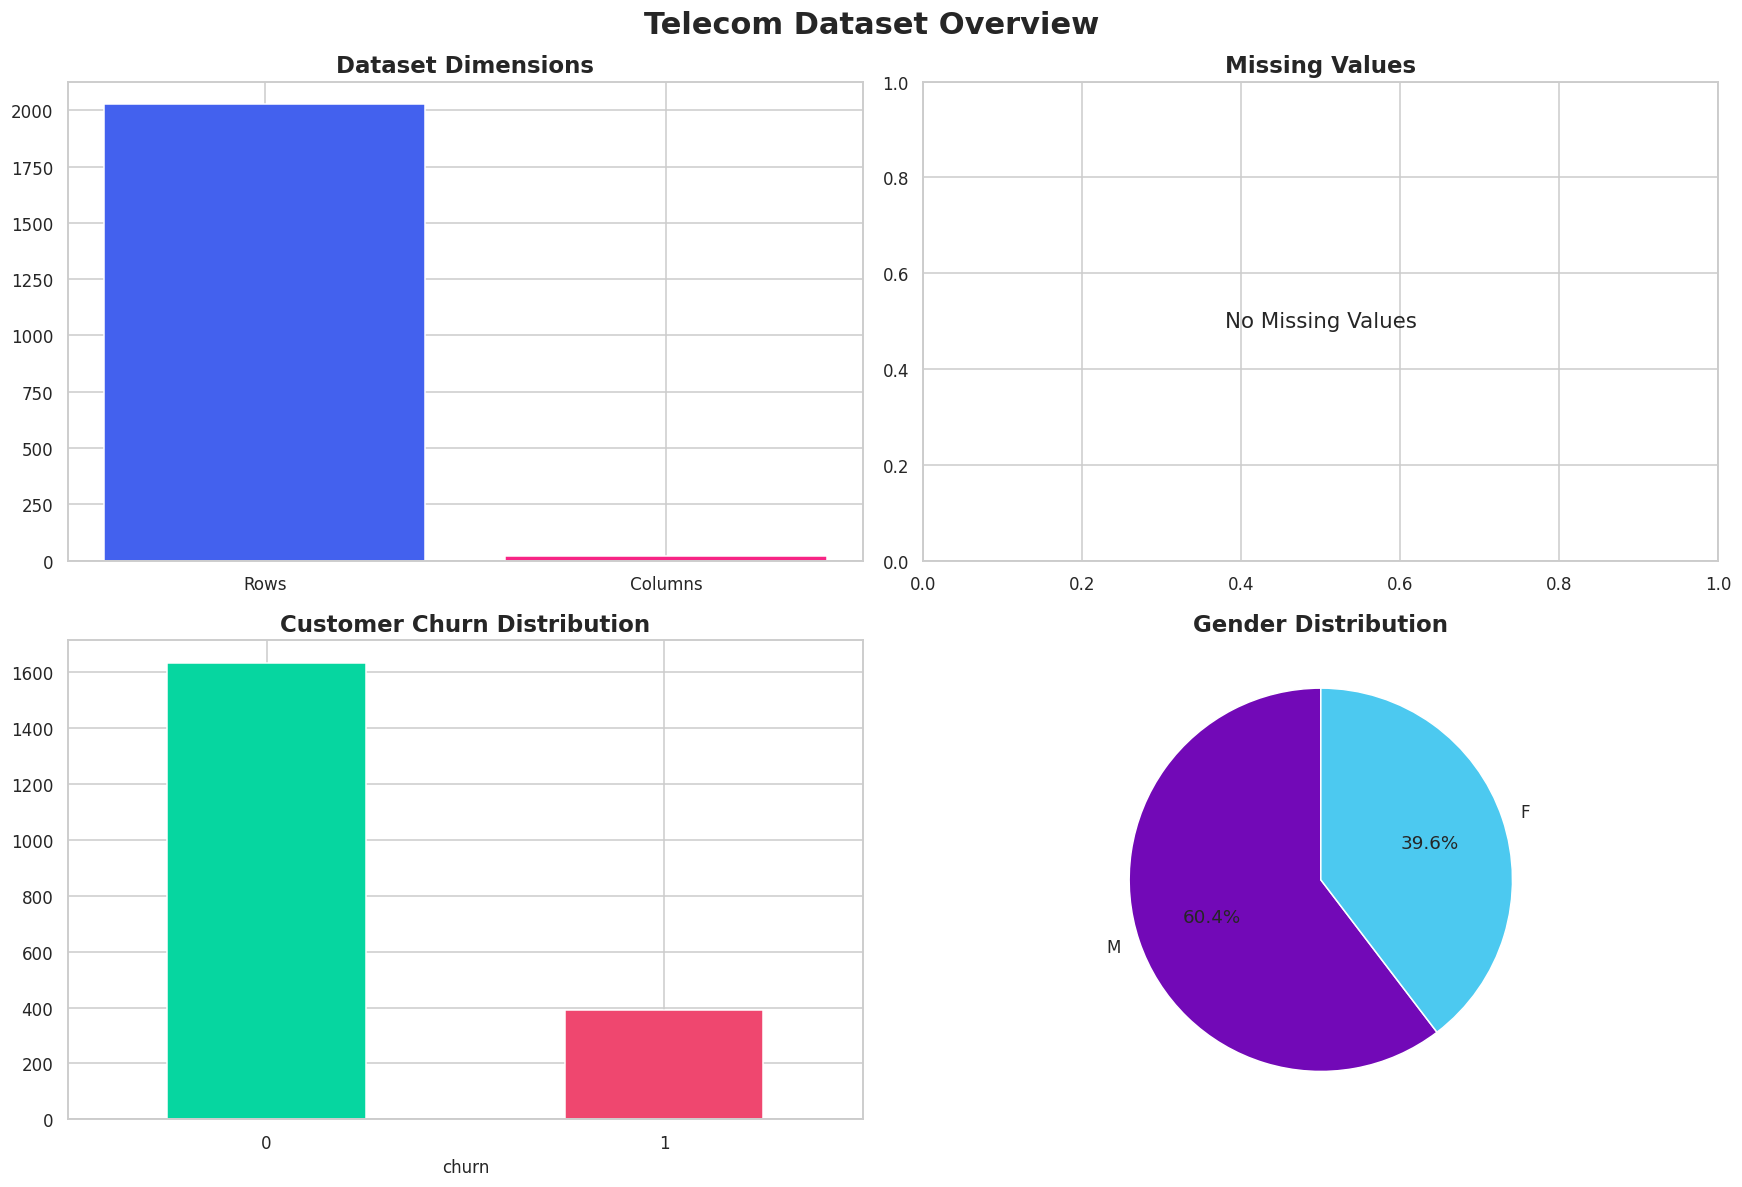

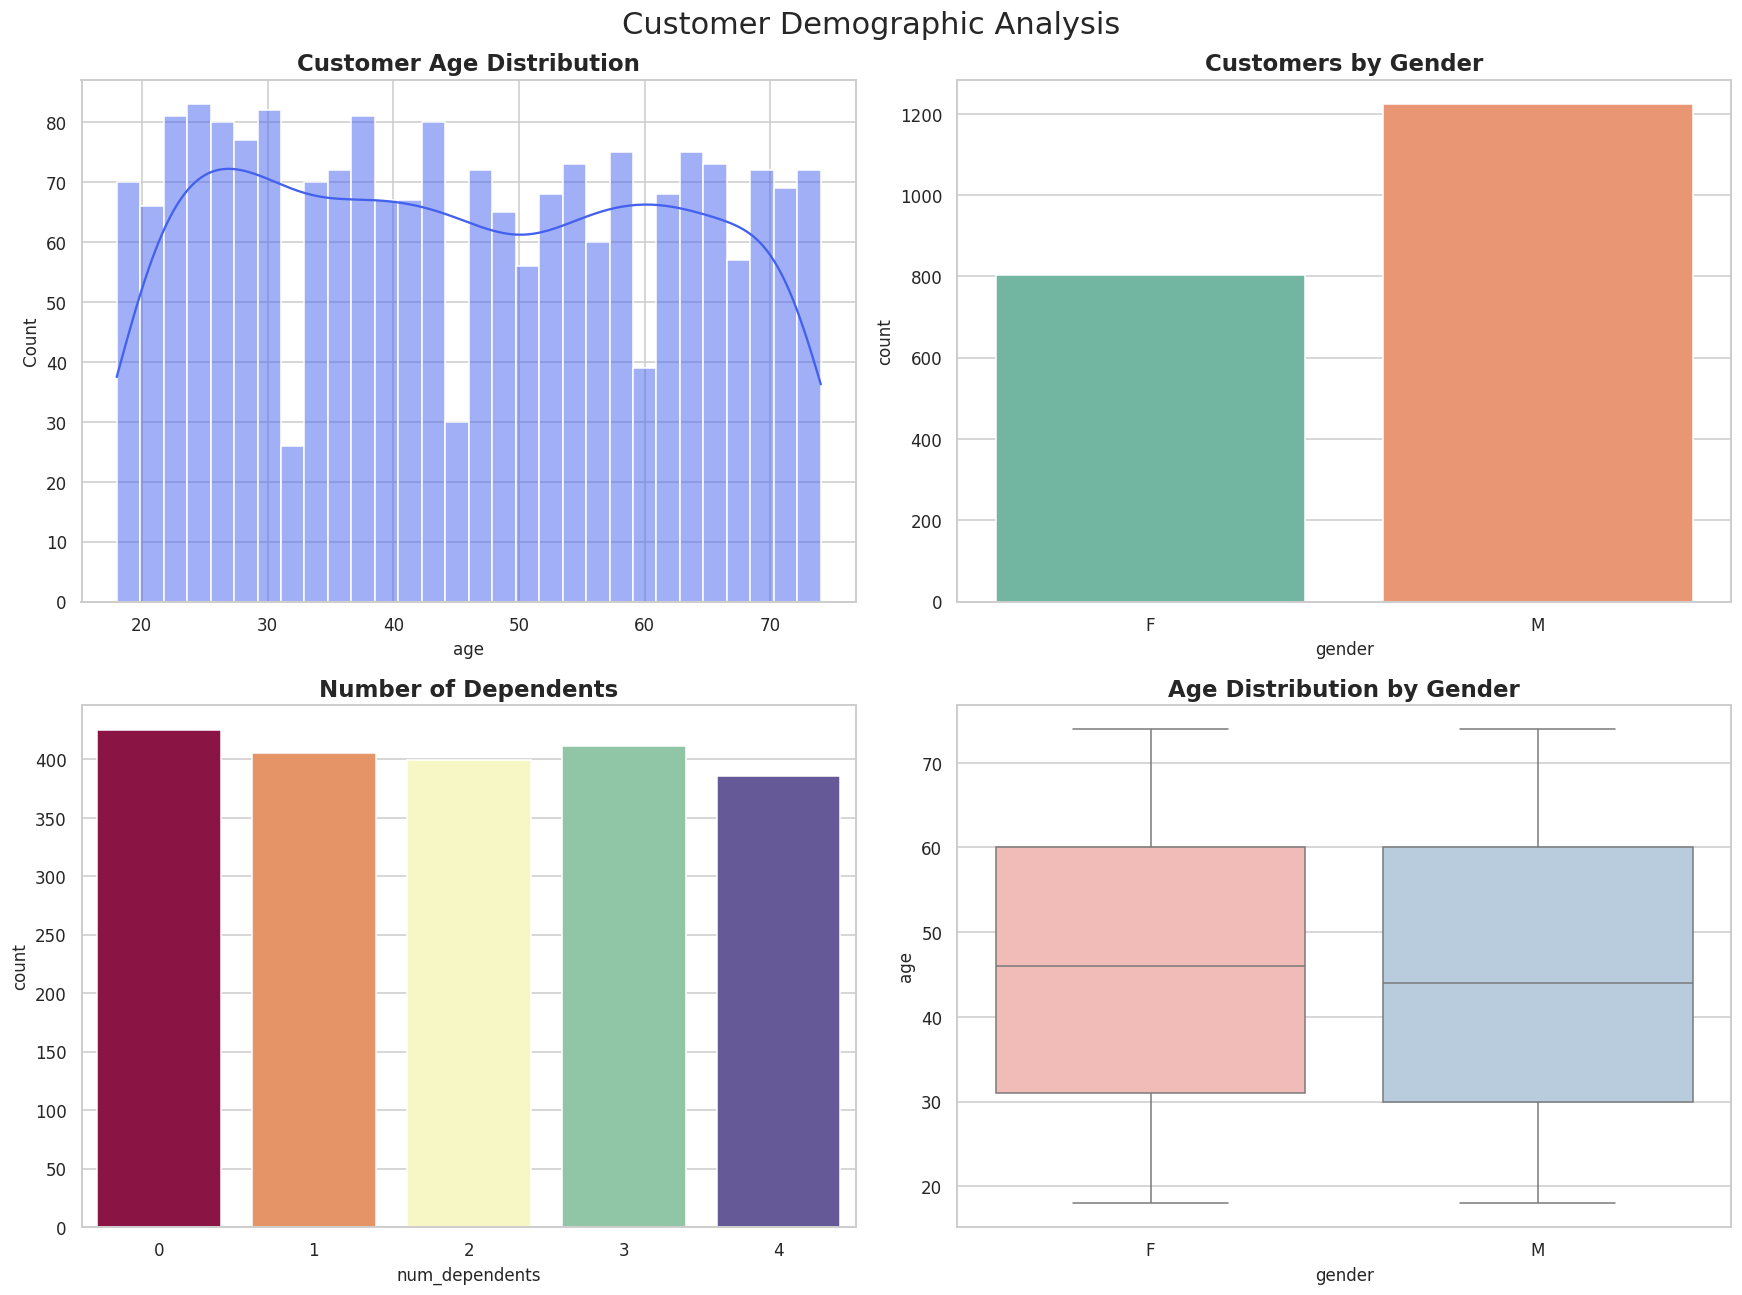

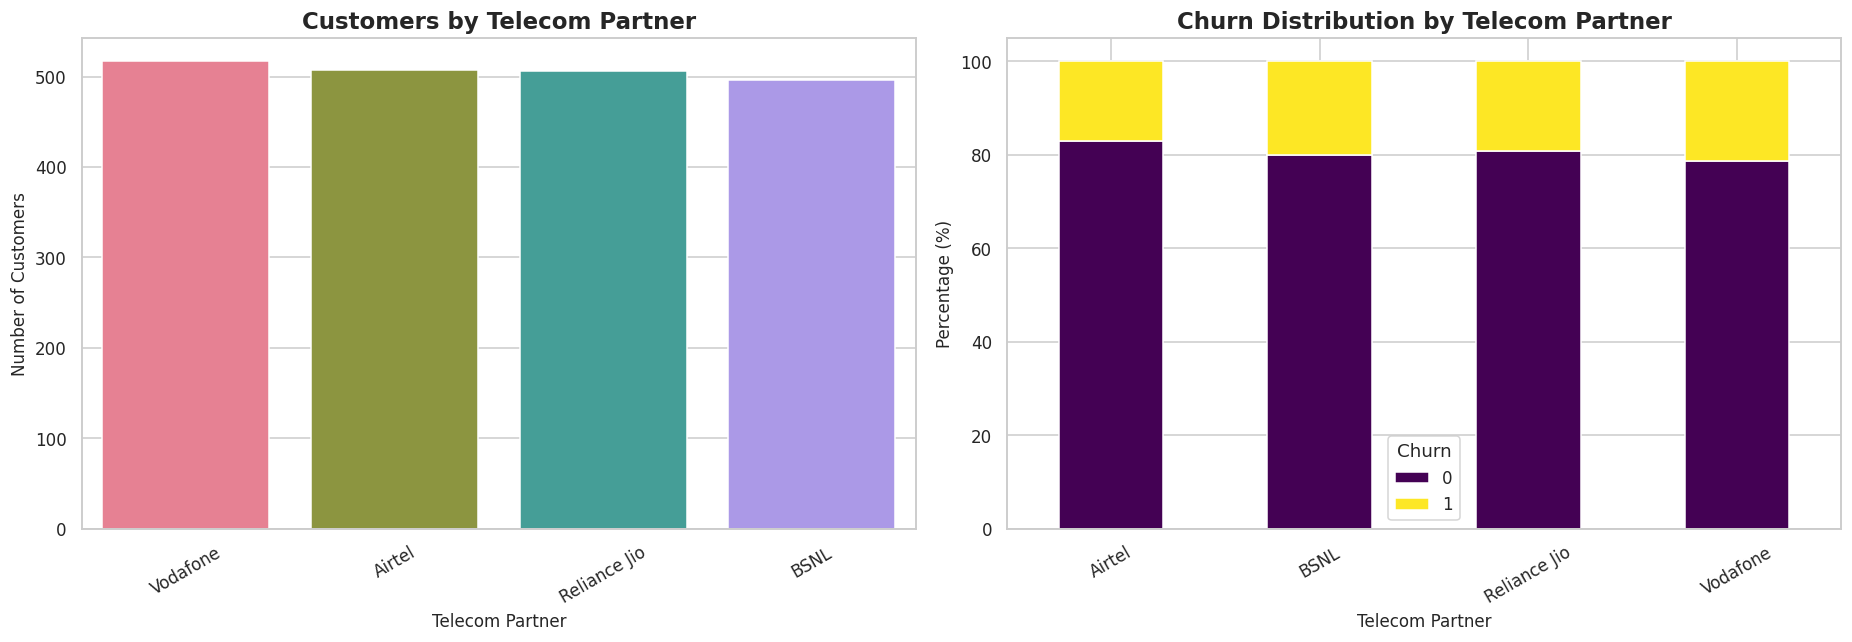

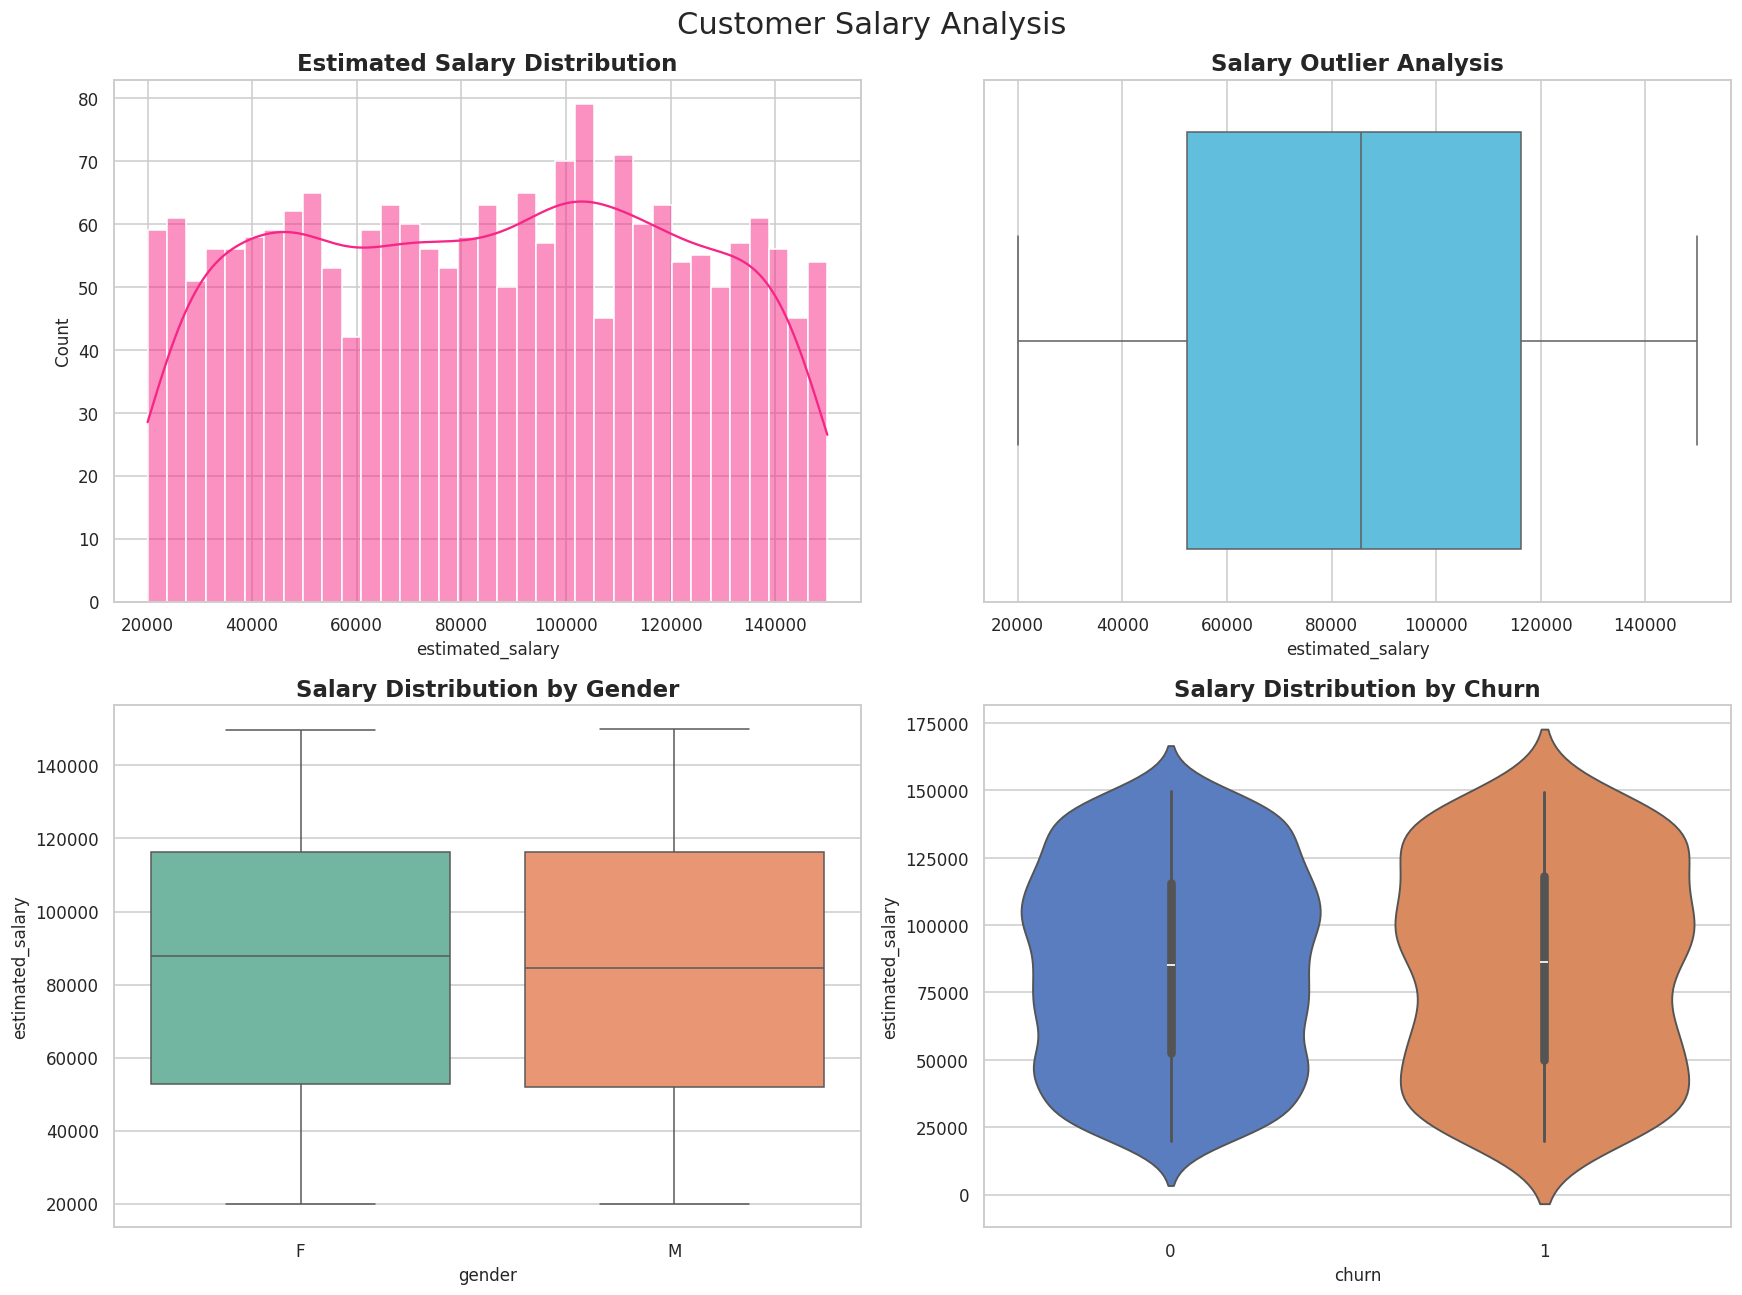

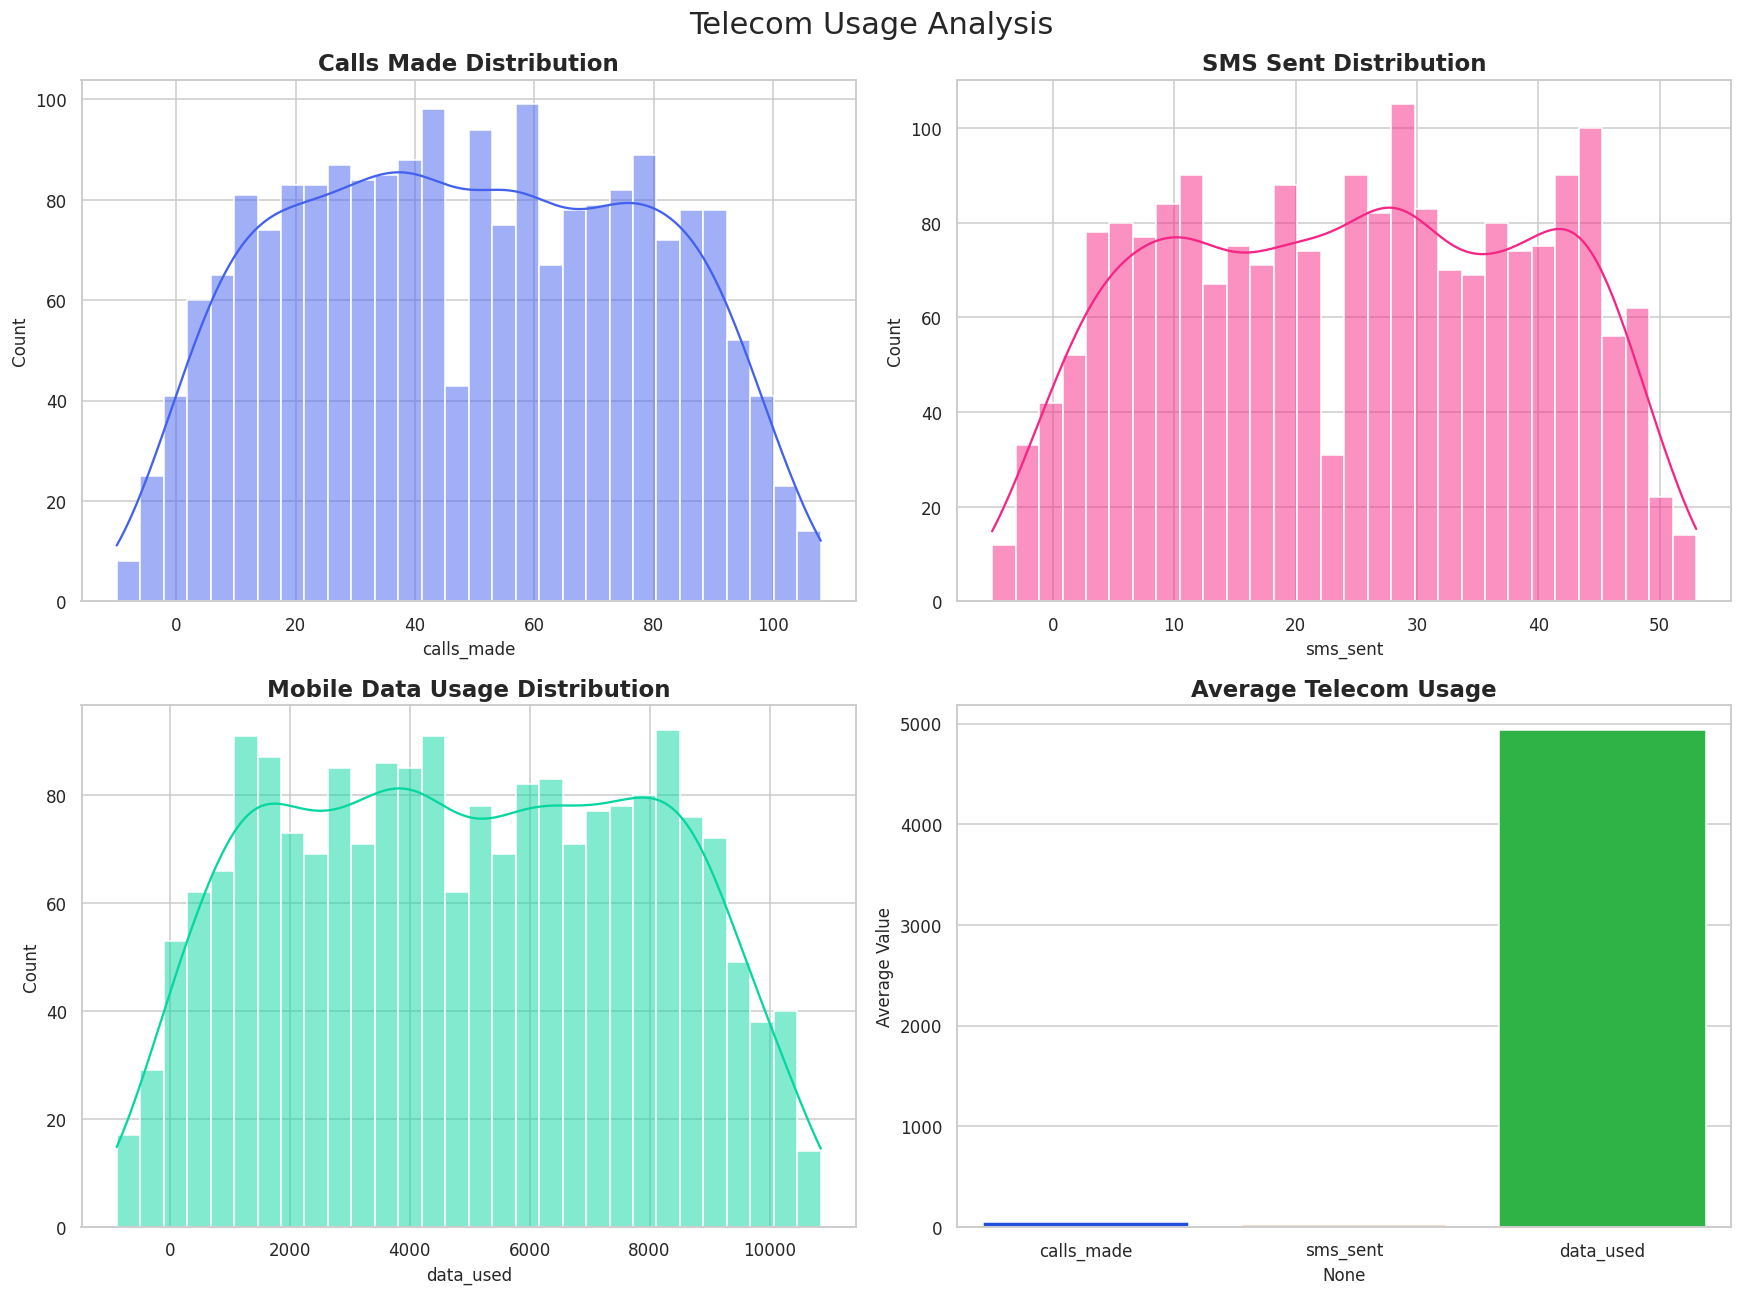

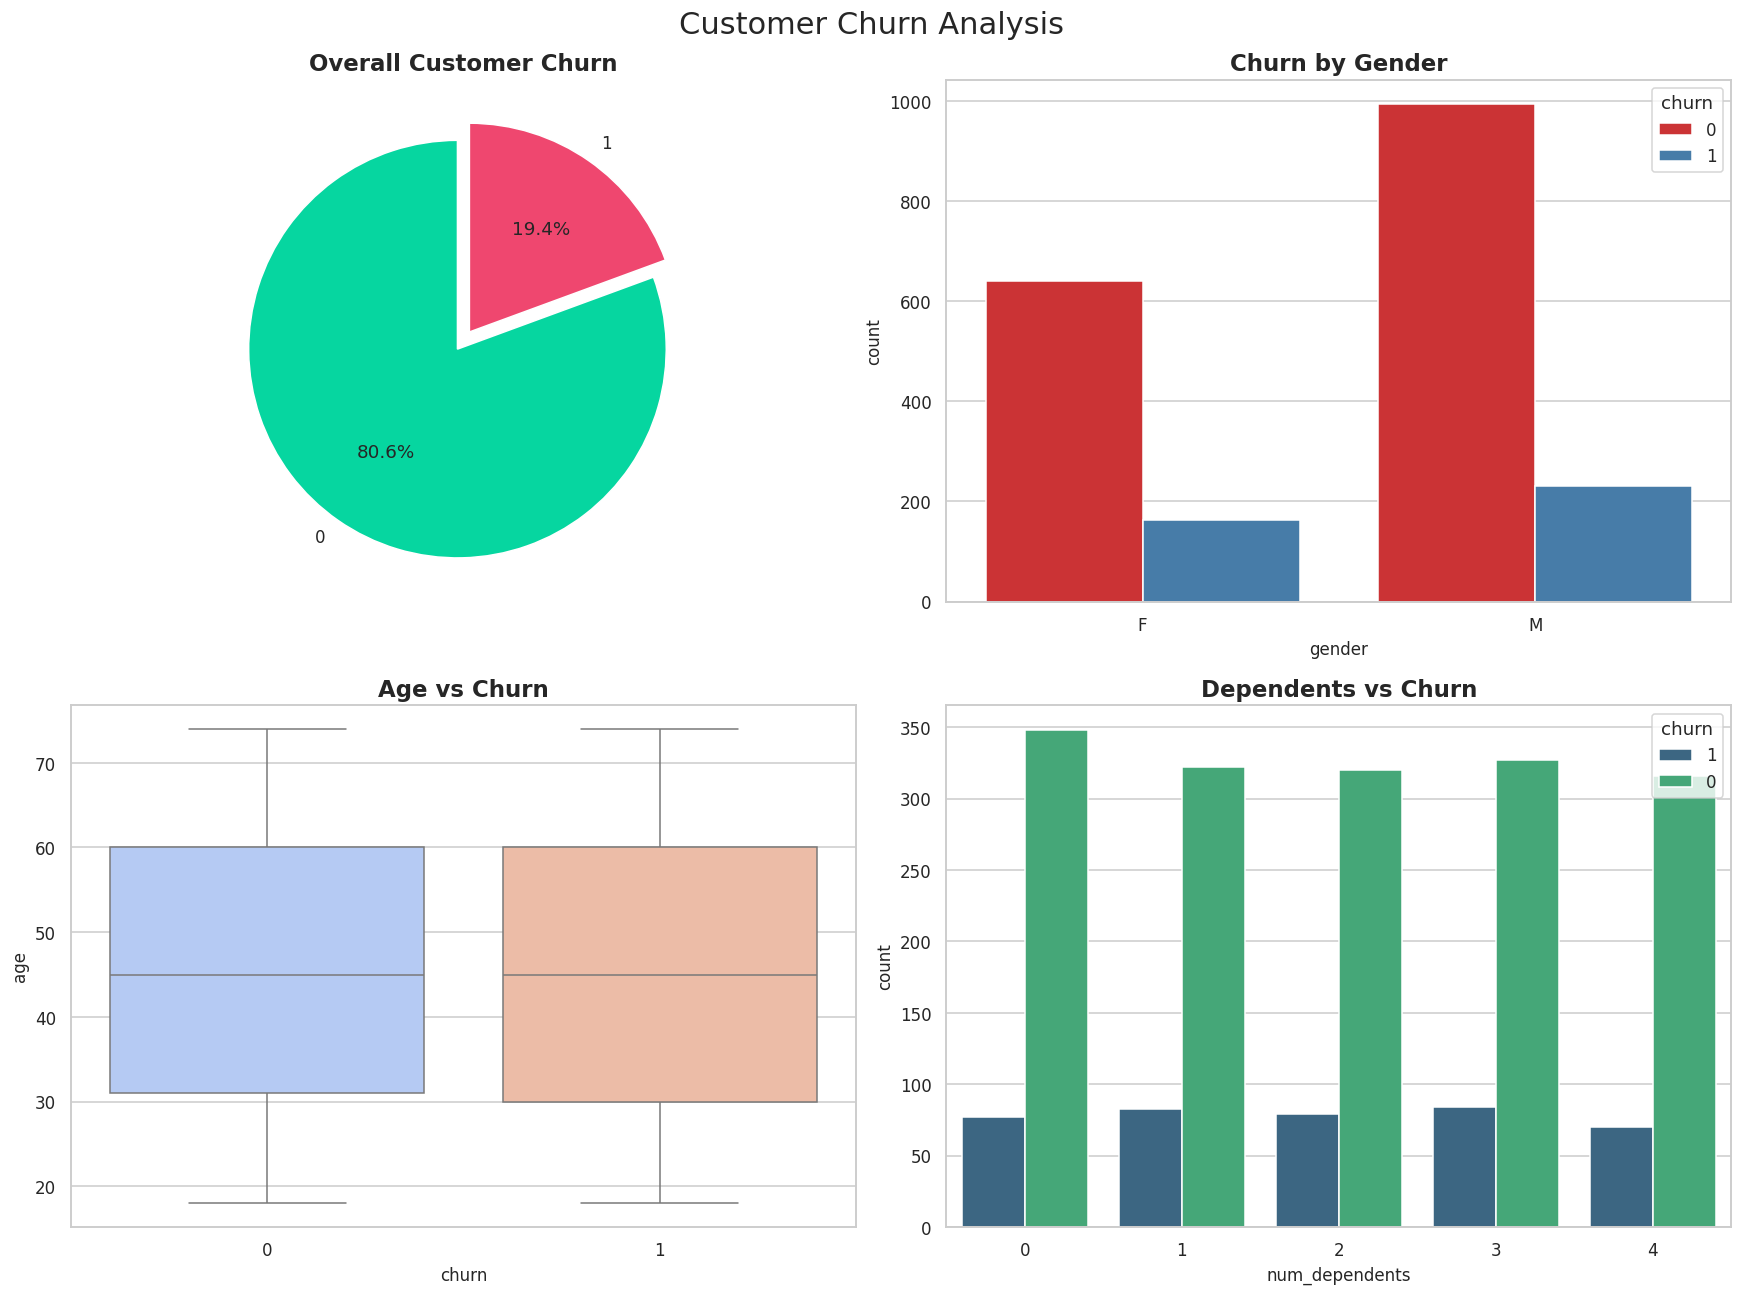

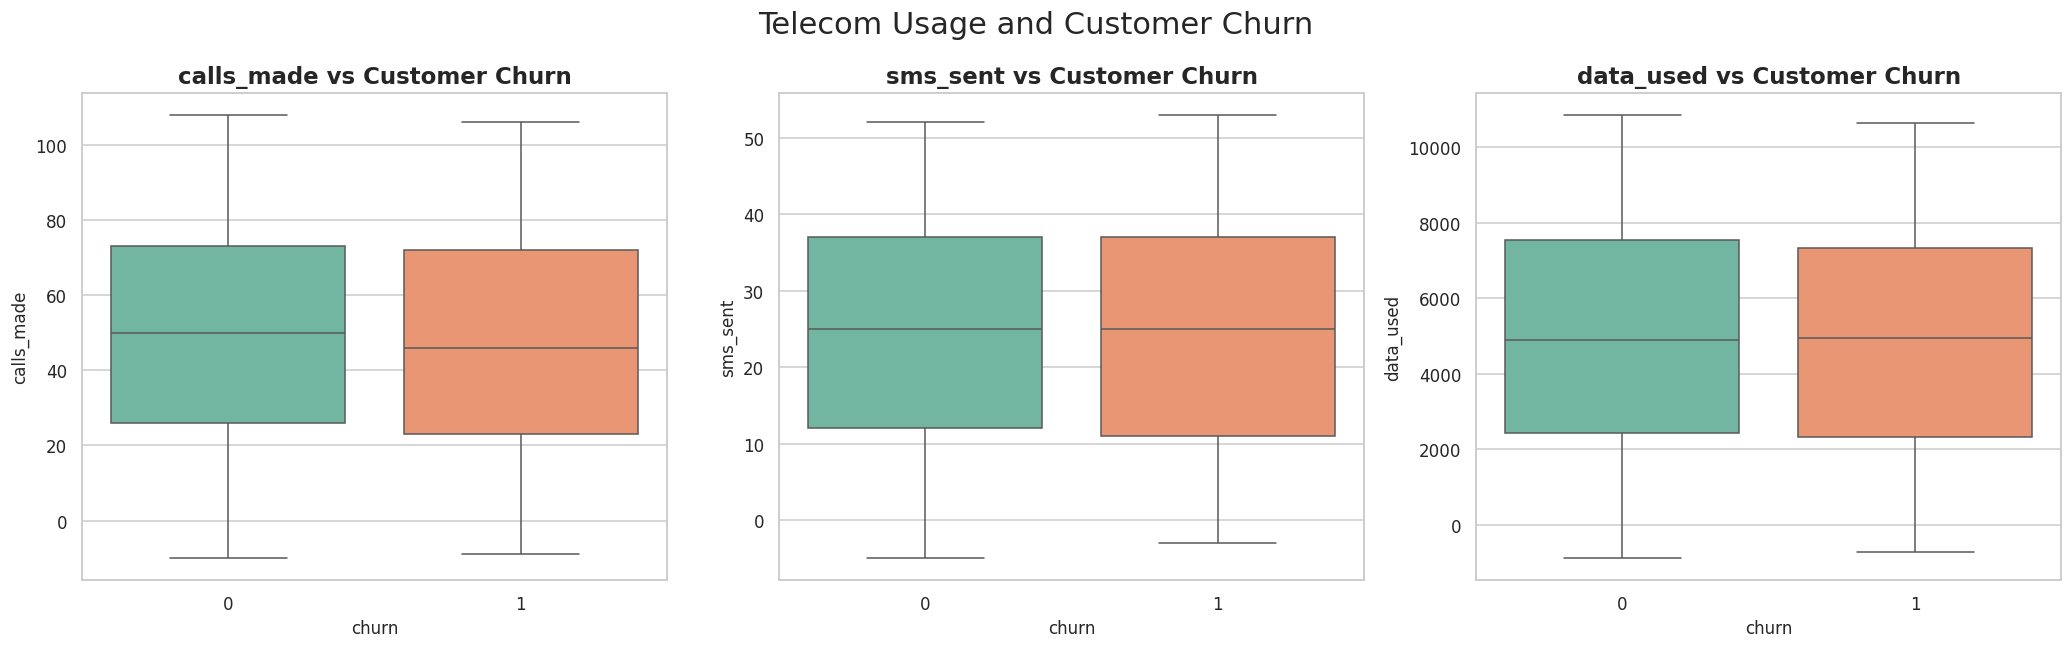

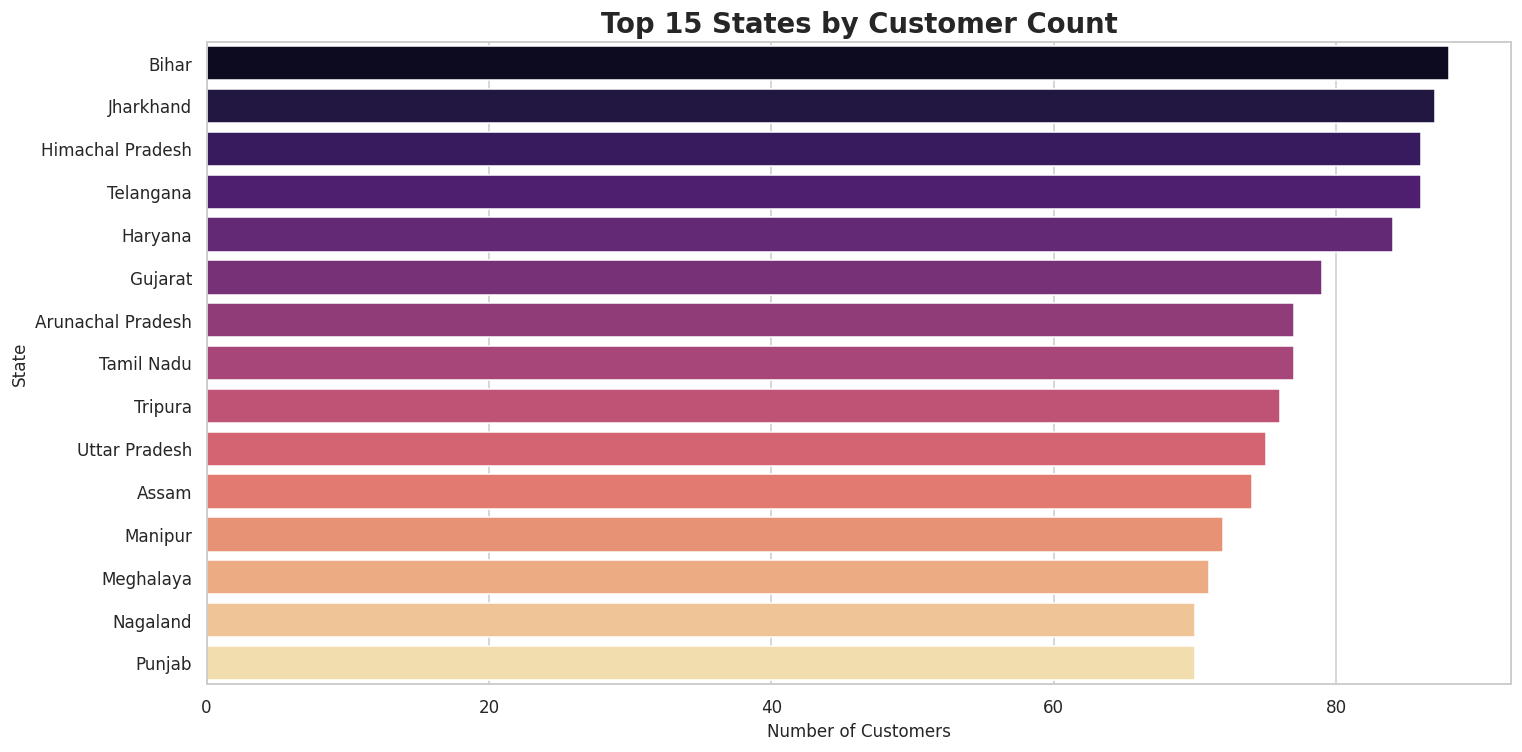

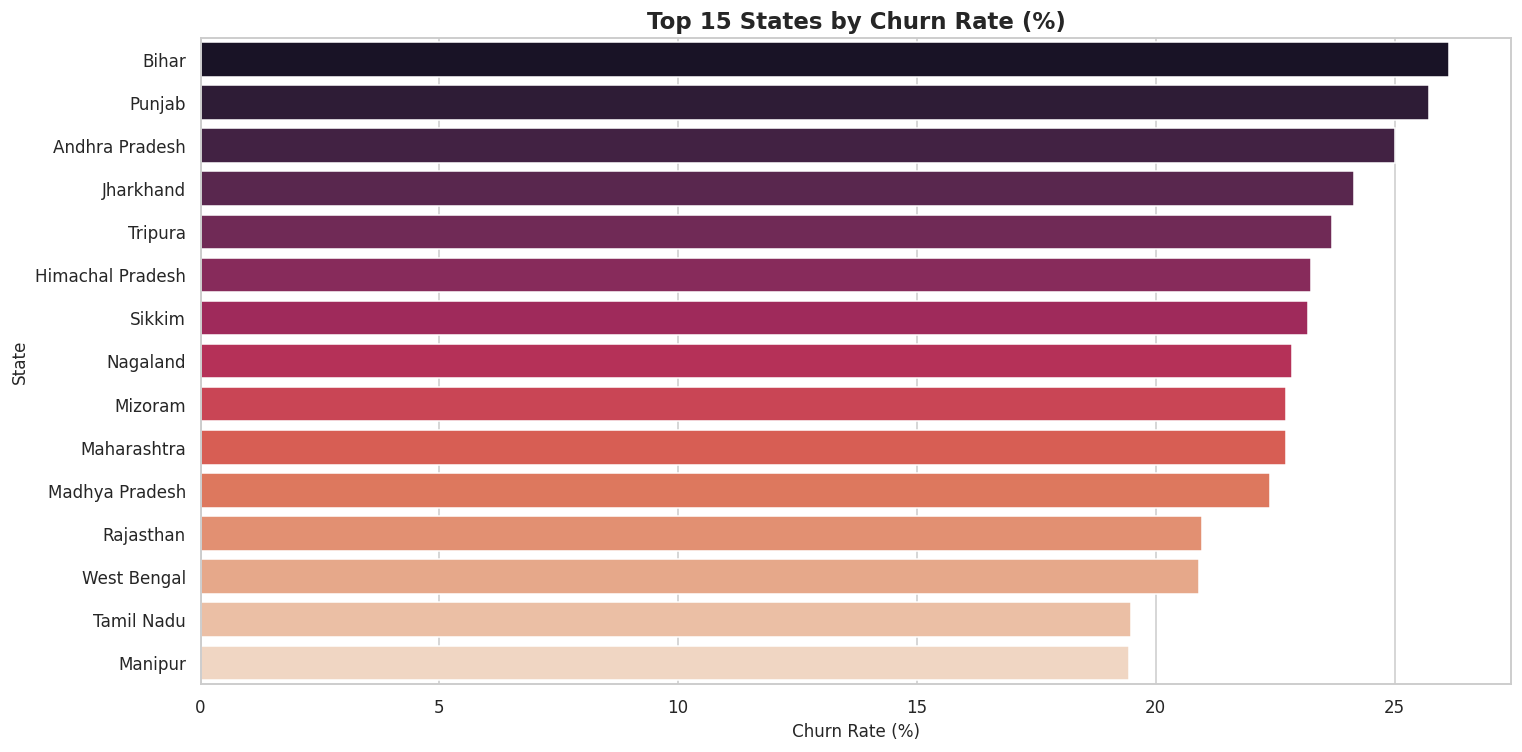

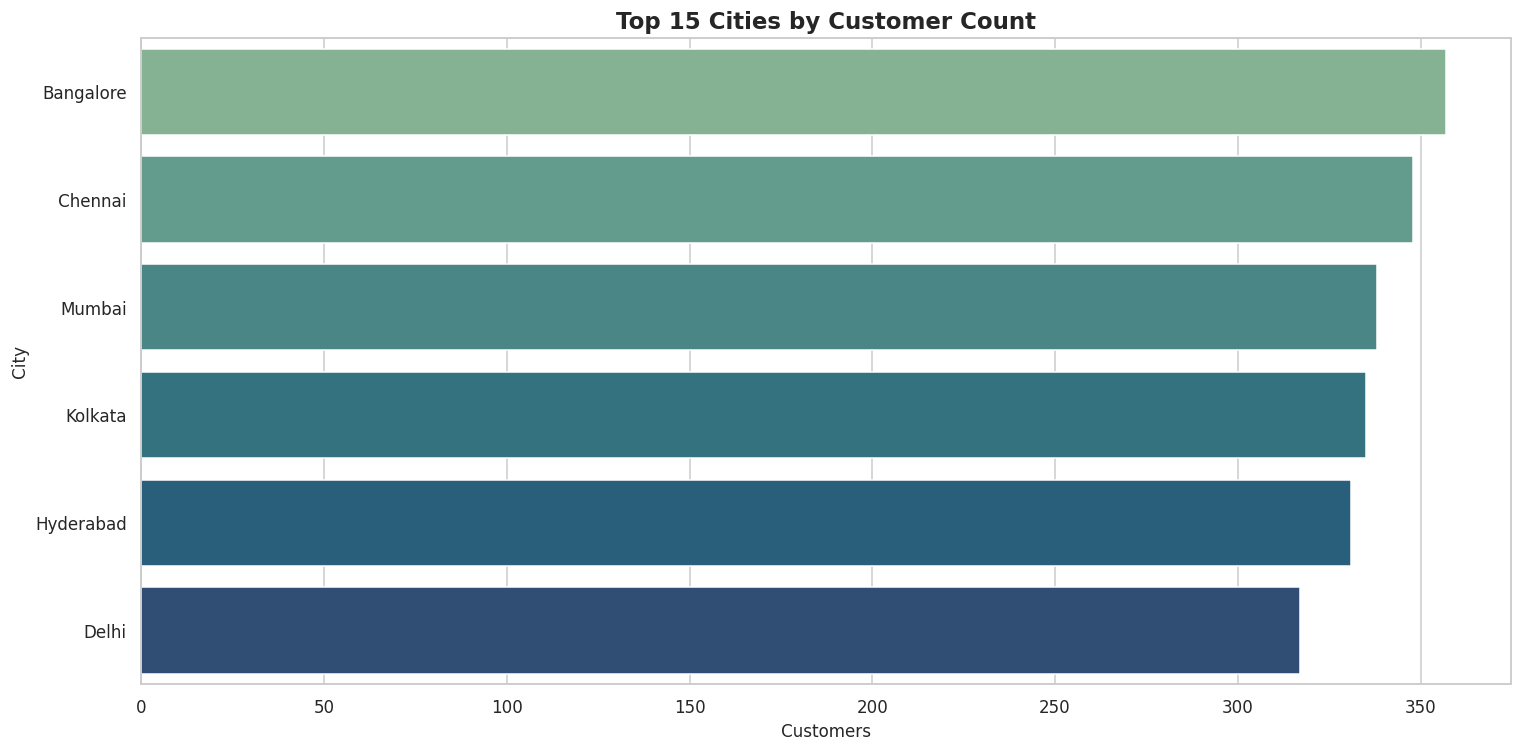

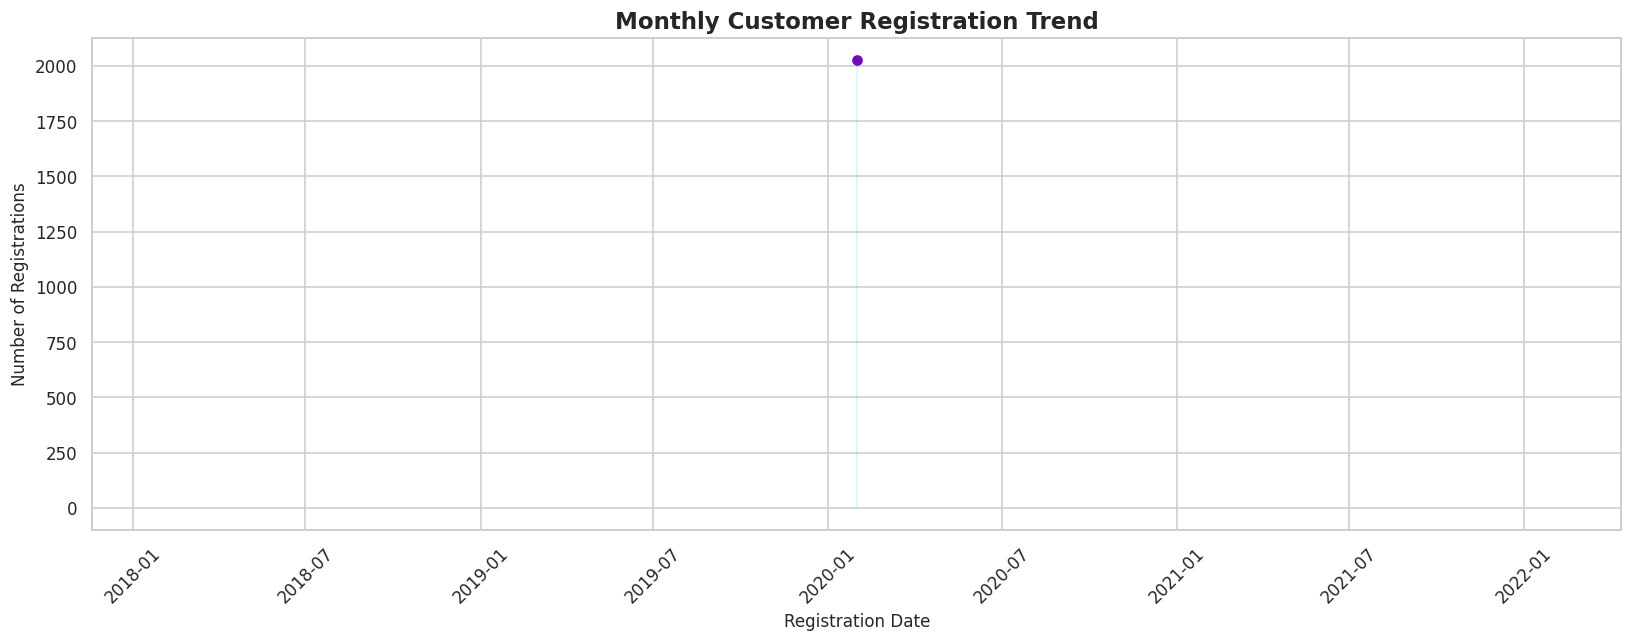

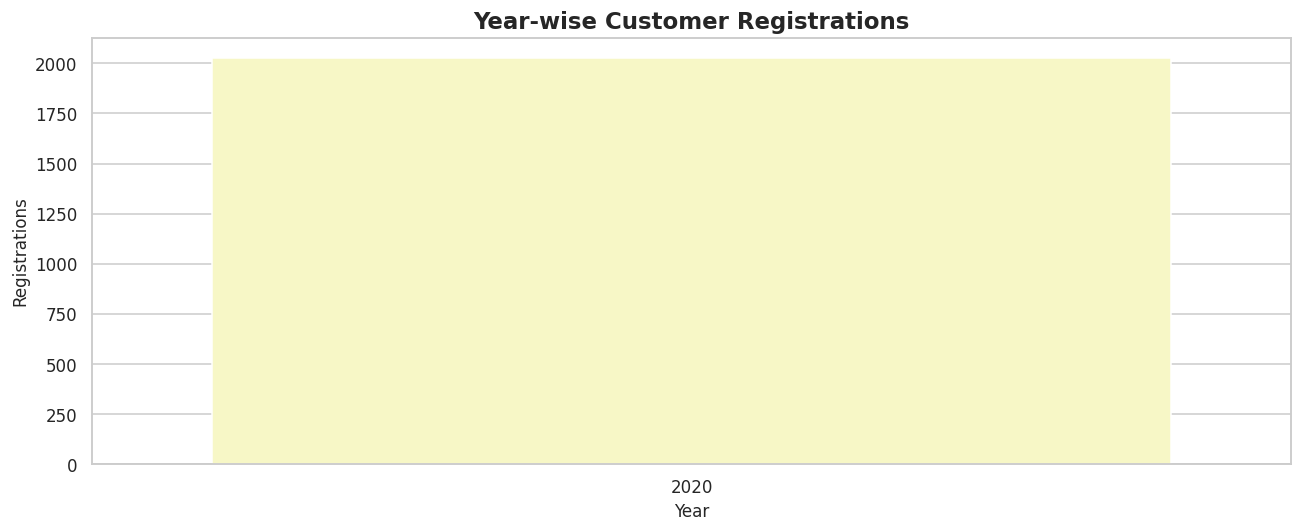

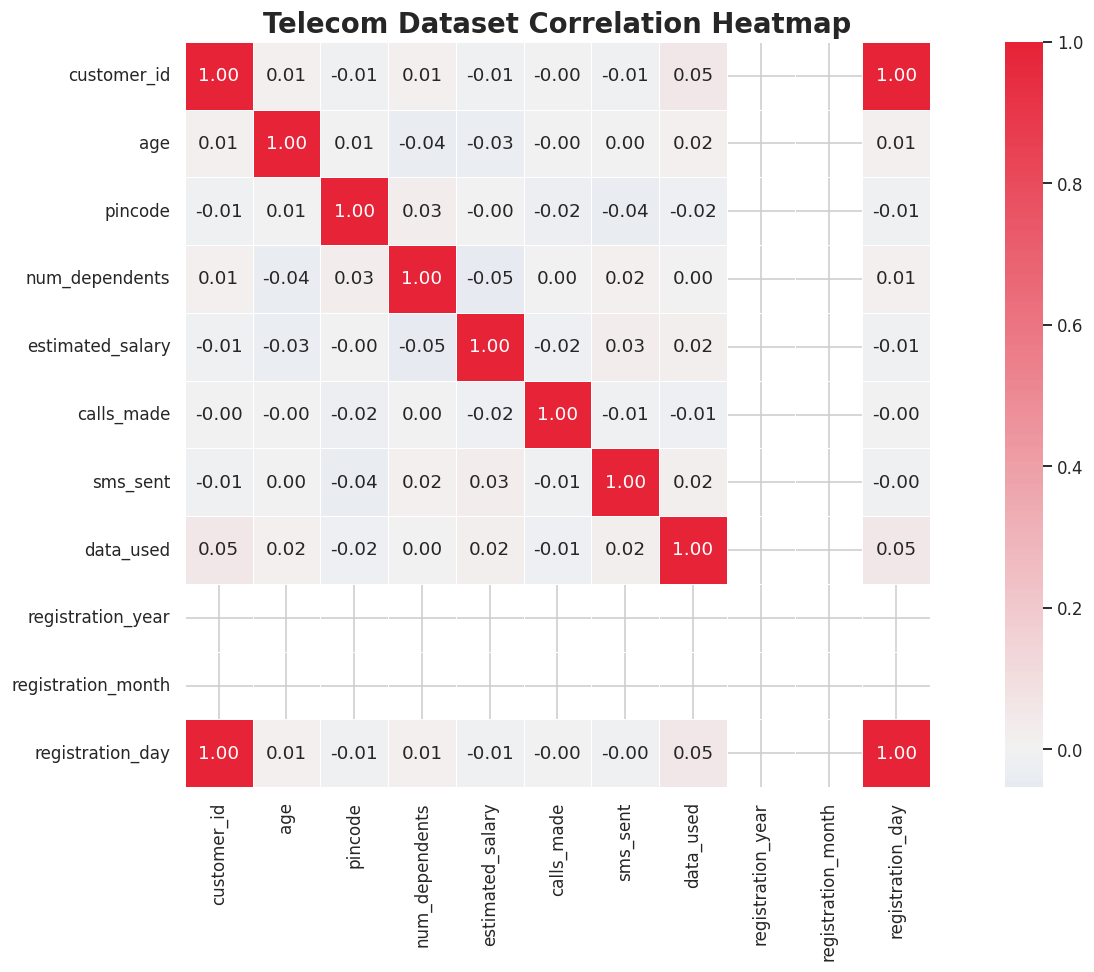

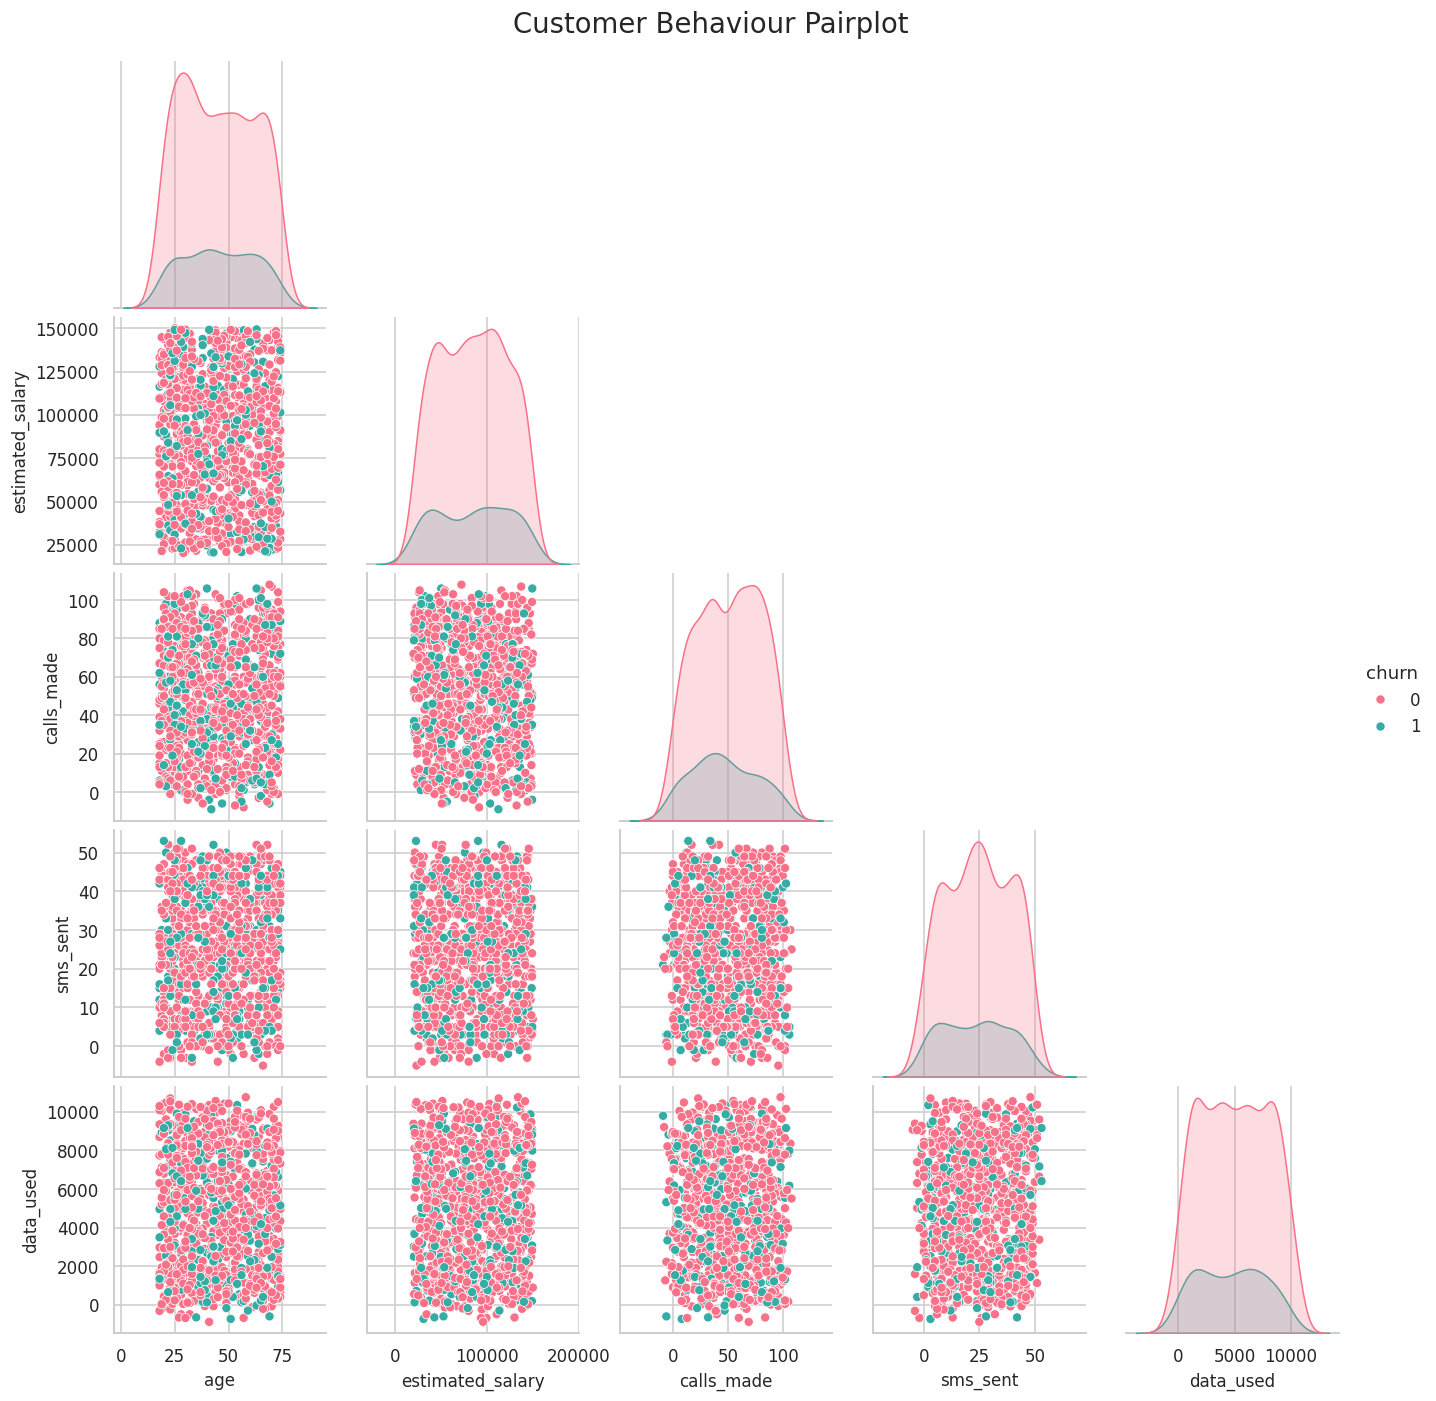


FINAL TELECOM CUSTOMER CHURN SUMMARY

Total Customers: 2,026

Gender Distribution:


gender
M    1223
F     803
Name: count, dtype: int64


Telecom Partner Distribution:


telecom_partner
Vodafone        517
Airtel          507
Reliance Jio    506
BSNL            496
Name: count, dtype: int64


Churn Distribution:


churn
0    1633
1     393
Name: count, dtype: int64

... (3 outputs left out)

city
Bangalore    357
Chennai      348
Mumbai       338
Kolkata      335
Hyderabad    331
Delhi        317
Name: count, dtype: int64


Top 10 Customer States:


state
Bihar                88
Jharkhand            87
Himachal Pradesh     86
Telangana            86
Haryana              84
Gujarat              79
Arunachal Pradesh    77
Tamil Nadu           77
Tripura              76
Uttar Pradesh        75
Name: count, dtype: int64


Top Telecom Partner by Customer Count:
Vodafone

VISUALIZATION COMPLETED SUCCESSFULLY!


In [13]:
import plotly.express as px
import plotly.graph_objects as go

from matplotlib.colors import LinearSegmentedColormap

# ============================================================
# 2. DATA PREPARATION
# ============================================================

# If your dataset is already loaded, skip this line.
# df = pd.read_csv('/kaggle/input/your-dataset/telecom.csv')

df = df.copy()

print("=" * 70)
print("TELECOM CUSTOMER CHURN DATASET")
print("=" * 70)

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# Convert date column
df['date_of_registration'] = pd.to_datetime(
    df['date_of_registration'], errors='coerce'
)

# Clean churn labels if necessary
df['churn'] = df['churn'].astype(str).str.strip()

# Extract date features
df['registration_year'] = df['date_of_registration'].dt.year
df['registration_month'] = df['date_of_registration'].dt.month
df['registration_month_name'] = (
    df['date_of_registration'].dt.month_name()
)

df['registration_day'] = df['date_of_registration'].dt.day
df['registration_day_name'] = (
    df['date_of_registration'].dt.day_name()
)

# ============================================================
# 3. VISUALIZATION STYLE
# ============================================================

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 110

# Different color palettes
colors = [
    '#4361EE', '#F72585', '#4CC9F0',
    '#7209B7', '#F77F00', '#2A9D8F',
    '#E63946', '#FFBE0B', '#8338EC',
    '#06D6A0'
]

# ============================================================
# 4. DATASET OVERVIEW
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Dataset dimensions
axes[0, 0].bar(
    ['Rows', 'Columns'],
    [df.shape[0], df.shape[1]],
    color=['#4361EE', '#F72585']
)
axes[0, 0].set_title('Dataset Dimensions')

# Missing values
missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) > 0:
    missing.plot(
        kind='bar', ax=axes[0, 1],
        color='#F77F00'
    )
    axes[0, 1].set_title('Missing Values by Column')
    axes[0, 1].tick_params(axis='x', rotation=45)
else:
    axes[0, 1].text(
        0.5, 0.5, 'No Missing Values',
        ha='center', va='center', fontsize=14
    )
    axes[0, 1].set_title('Missing Values')

# Churn distribution
df['churn'].value_counts().plot(
    kind='bar',
    ax=axes[1, 0],
    color=['#06D6A0', '#EF476F', '#4361EE']
)
axes[1, 0].set_title('Customer Churn Distribution')
axes[1, 0].tick_params(axis='x', rotation=0)

# Gender distribution
df['gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1, 1],
    colors=['#7209B7', '#4CC9F0'],
    startangle=90
)
axes[1, 1].set_title('Gender Distribution')
axes[1, 1].set_ylabel('')

plt.suptitle('Telecom Dataset Overview', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 5. CUSTOMER DEMOGRAPHICS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Age distribution
sns.histplot(
    data=df, x='age', bins=30,
    kde=True, color='#4361EE',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Customer Age Distribution')

# Gender distribution
sns.countplot(
    data=df, x='gender',
    hue='gender', palette='Set2',
    legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title('Customers by Gender')

# Dependents distribution
sns.countplot(
    data=df, x='num_dependents',
    hue='num_dependents',
    palette='Spectral',
    legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title('Number of Dependents')

# Age by gender
sns.boxplot(
    data=df, x='gender', y='age',
    hue='gender', palette='Pastel1',
    legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title('Age Distribution by Gender')

plt.suptitle('Customer Demographic Analysis', fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 6. TELECOM PARTNER ANALYSIS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

partner_counts = df['telecom_partner'].value_counts()

sns.barplot(
    x=partner_counts.index,
    y=partner_counts.values,
    hue=partner_counts.index,
    palette='husl',
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Customers by Telecom Partner')
axes[0].set_xlabel('Telecom Partner')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=30)

# Churn rate by partner
partner_churn = pd.crosstab(
    df['telecom_partner'],
    df['churn'],
    normalize='index'
) * 100

partner_churn.plot(
    kind='bar',
    stacked=True,
    colormap='viridis',
    ax=axes[1]
)

axes[1].set_title('Churn Distribution by Telecom Partner')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('Telecom Partner')
axes[1].legend(title='Churn')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# ============================================================
# 7. CUSTOMER SALARY ANALYSIS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Salary distribution
sns.histplot(
    df['estimated_salary'].dropna(),
    kde=True,
    bins=35,
    color='#F72585',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Estimated Salary Distribution')

# Salary boxplot
sns.boxplot(
    x=df['estimated_salary'],
    color='#4CC9F0',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Salary Outlier Analysis')

# Salary by gender
sns.boxplot(
    data=df,
    x='gender',
    y='estimated_salary',
    hue='gender',
    palette='Set2',
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Salary Distribution by Gender')

# Salary by churn
sns.violinplot(
    data=df,
    x='churn',
    y='estimated_salary',
    hue='churn',
    palette='muted',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Salary Distribution by Churn')

plt.suptitle('Customer Salary Analysis', fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 8. TELECOM USAGE ANALYSIS
# ============================================================

usage_columns = [
    'calls_made',
    'sms_sent',
    'data_used'
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Calls distribution
sns.histplot(
    df['calls_made'].dropna(),
    bins=30, kde=True,
    color='#4361EE',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Calls Made Distribution')

# SMS distribution
sns.histplot(
    df['sms_sent'].dropna(),
    bins=30, kde=True,
    color='#F72585',
    ax=axes[0, 1]
)
axes[0, 1].set_title('SMS Sent Distribution')

# Data usage distribution
sns.histplot(
    df['data_used'].dropna(),
    bins=30, kde=True,
    color='#06D6A0',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Mobile Data Usage Distribution')

# Usage comparison
usage_avg = df[usage_columns].mean()

sns.barplot(
    x=usage_avg.index,
    y=usage_avg.values,
    hue=usage_avg.index,
    palette='bright',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Average Telecom Usage')
axes[1, 1].set_ylabel('Average Value')

plt.suptitle('Telecom Usage Analysis', fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 9. CHURN ANALYSIS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Churn count
churn_counts = df['churn'].value_counts()

axes[0, 0].pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    colors=['#06D6A0', '#EF476F', '#4361EE'],
    explode=[0.05] * len(churn_counts),
    startangle=90
)
axes[0, 0].set_title('Overall Customer Churn')

# Churn by gender
sns.countplot(
    data=df,
    x='gender',
    hue='churn',
    palette='Set1',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Churn by Gender')

# Churn by age
sns.boxplot(
    data=df,
    x='churn',
    y='age',
    hue='churn',
    palette='coolwarm',
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Age vs Churn')

# Churn by dependents
sns.countplot(
    data=df,
    x='num_dependents',
    hue='churn',
    palette='viridis',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Dependents vs Churn')

plt.suptitle('Customer Churn Analysis', fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 10. USAGE PATTERNS VS CHURN
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for i, col in enumerate(usage_columns):

    sns.boxplot(
        data=df,
        x='churn',
        y=col,
        hue='churn',
        palette='Set2',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} vs Customer Churn')

plt.suptitle('Telecom Usage and Customer Churn', fontsize=20)
plt.tight_layout()
plt.show()

# ============================================================
# 11. STATE-WISE CUSTOMER ANALYSIS
# ============================================================

top_states = df['state'].value_counts().head(15)

plt.figure(figsize=(14, 7))

sns.barplot(
    x=top_states.values,
    y=top_states.index,
    hue=top_states.index,
    palette='magma',
    legend=False
)

plt.title('Top 15 States by Customer Count', fontsize=18)
plt.xlabel('Number of Customers')
plt.ylabel('State')
plt.tight_layout()
plt.show()

# State-wise churn rate
state_churn = pd.crosstab(
    df['state'],
    df['churn'],
    normalize='index'
) * 100

# Identify churned class
churn_labels = [
    label for label in df['churn'].unique()
    if label.lower() in ['1', 'yes', 'true', 'churned']
]

if churn_labels:
    state_churn_rate = (
        state_churn[churn_labels[0]]
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(14, 7))

    sns.barplot(
        x=state_churn_rate.values,
        y=state_churn_rate.index,
        hue=state_churn_rate.index,
        palette='rocket',
        legend=False
    )

    plt.title('Top 15 States by Churn Rate (%)')
    plt.xlabel('Churn Rate (%)')
    plt.ylabel('State')
    plt.tight_layout()
    plt.show()

# ============================================================
# 12. CITY-WISE CUSTOMER ANALYSIS
# ============================================================

top_cities = df['city'].value_counts().head(15)

plt.figure(figsize=(14, 7))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    hue=top_cities.index,
    palette='crest',
    legend=False
)

plt.title('Top 15 Cities by Customer Count')
plt.xlabel('Customers')
plt.ylabel('City')
plt.tight_layout()
plt.show()

# ============================================================
# 13. REGISTRATION TREND ANALYSIS
# ============================================================

registration_data = df.dropna(
    subset=['date_of_registration']
).copy()

if not registration_data.empty:

    monthly_registration = (
        registration_data
        .set_index('date_of_registration')
        .resample('ME')
        .size()
    )

    plt.figure(figsize=(15, 6))

    plt.plot(
        monthly_registration.index,
        monthly_registration.values,
        marker='o',
        linewidth=2.5,
        color='#7209B7'
    )

    plt.fill_between(
        monthly_registration.index,
        monthly_registration.values,
        alpha=0.2,
        color='#4CC9F0'
    )

    plt.title('Monthly Customer Registration Trend')
    plt.xlabel('Registration Date')
    plt.ylabel('Number of Registrations')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Registration by year
    yearly = registration_data['registration_year'].value_counts().sort_index()

    plt.figure(figsize=(12, 5))

    sns.barplot(
        x=yearly.index.astype(str),
        y=yearly.values,
        hue=yearly.index.astype(str),
        palette='Spectral',
        legend=False
    )

    plt.title('Year-wise Customer Registrations')
    plt.xlabel('Year')
    plt.ylabel('Registrations')
    plt.tight_layout()
    plt.show()

# ============================================================
# 14. CORRELATION HEATMAP
# ============================================================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 9))

correlation = numeric_df.corr()

custom_cmap = sns.diverging_palette(
    250, 10, s=90, l=50, as_cmap=True
)

sns.heatmap(
    correlation,
    annot=True,
    cmap=custom_cmap,
    fmt='.2f',
    linewidths=0.5,
    center=0,
    square=True
)

plt.title('Telecom Dataset Correlation Heatmap', fontsize=18)
plt.tight_layout()
plt.show()

# ============================================================
# 15. PAIRPLOT - CUSTOMER BEHAVIOUR
# ============================================================

pair_columns = [
    'age',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used',
    'churn'
]

pair_data = df[pair_columns].dropna()

if len(pair_data) > 1000:
    pair_data = pair_data.sample(1000, random_state=42)

sns.pairplot(
    pair_data,
    hue='churn',
    palette='husl',
    diag_kind='kde',
    corner=True
)

plt.suptitle(
    'Customer Behaviour Pairplot',
    y=1.02,
    fontsize=18
)

plt.show()

# ============================================================
# 16. INTERACTIVE CHURN ANALYSIS - FIXED PLOTLY
# ============================================================

import plotly.express as px
import pandas as pd
import numpy as np

# Create a separate visualization dataset
plot_df = df.copy()

# Convert columns to numeric
numeric_cols = ['age', 'estimated_salary', 'data_used']

for col in numeric_cols:
    plot_df[col] = pd.to_numeric(
        plot_df[col], errors='coerce'
    )

# Remove missing and infinite values
plot_df = plot_df.replace(
    [np.inf, -np.inf], np.nan
)

plot_df = plot_df.dropna(
    subset=['age', 'estimated_salary', 'data_used', 'churn']
)

# Fix negative bubble sizes
# Negative values are clipped to zero for visualization
plot_df['data_used_size'] = plot_df['data_used'].clip(lower=0)

# Ensure bubble sizes are valid
plot_df['data_used_size'] = plot_df['data_used_size'].fillna(0)

# Create interactive scatter plot
fig = px.scatter(
    plot_df,
    x='age',
    y='estimated_salary',
    color='churn',
    size='data_used_size',
    size_max=25,
    hover_data=[
        'telecom_partner',
        'gender',
        'city',
        'calls_made',
        'sms_sent',
        'data_used'
    ],
    title='Interactive Telecom Customer Churn Analysis',
    color_discrete_sequence=px.colors.qualitative.Bold,
    opacity=0.75
)

fig.update_layout(
    template='plotly_white',
    width=1200,
    height=700,
    title_x=0.5,
    font=dict(size=12),
    legend_title='Customer Churn',
    xaxis_title='Customer Age',
    yaxis_title='Estimated Salary'
)

fig.show()

# ============================================================
# 17. INTERACTIVE TELECOM PARTNER ANALYSIS
# ============================================================

partner_usage = (
    df.groupby('telecom_partner')[usage_columns]
    .mean()
    .reset_index()
)

fig = px.bar(
    partner_usage,
    x='telecom_partner',
    y=usage_columns,
    barmode='group',
    title='Average Usage by Telecom Partner',
    color_discrete_sequence=px.colors.qualitative.Vivid
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=600
)

fig.show()

# ============================================================
# 18. INTERACTIVE STATE-WISE CHURN
# ============================================================

state_summary = (
    df.groupby('state')
    .agg(
        total_customers=('customer_id', 'count'),
        avg_age=('age', 'mean'),
        avg_salary=('estimated_salary', 'mean'),
        avg_calls=('calls_made', 'mean'),
        avg_data=('data_used', 'mean')
    )
    .reset_index()
)

fig = px.scatter(
    state_summary,
    x='total_customers',
    y='avg_data',
    size='avg_salary',
    color='avg_age',
    hover_name='state',
    title='State-wise Customer Distribution and Data Usage',
    color_continuous_scale='Turbo'
)

fig.update_layout(template='plotly_white')
fig.show()

# ============================================================
# 19. CUSTOMER USAGE DISTRIBUTION - INTERACTIVE
# ============================================================

usage_long = df.melt(
    id_vars=['churn'],
    value_vars=usage_columns,
    var_name='Usage Type',
    value_name='Usage Value'
)

fig = px.box(
    usage_long,
    x='Usage Type',
    y='Usage Value',
    color='churn',
    title='Interactive Telecom Usage vs Churn',
    color_discrete_sequence=px.colors.qualitative.Set1
)

fig.update_layout(template='plotly_white')
fig.show()

# ============================================================
# 20. FINAL CUSTOMER CHURN SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL TELECOM CUSTOMER CHURN SUMMARY")
print("=" * 70)

total_customers = len(df)

print(f"\nTotal Customers: {total_customers:,}")

print("\nGender Distribution:")
display(df['gender'].value_counts())

print("\nTelecom Partner Distribution:")
display(df['telecom_partner'].value_counts())

print("\nChurn Distribution:")
display(df['churn'].value_counts())

print("\nAverage Customer Age:", round(df['age'].mean(), 2))

print(
    "Average Estimated Salary:",
    round(df['estimated_salary'].mean(), 2)
)

print("\nAverage Telecom Usage:")
display(df[usage_columns].mean())

print("\nTop 10 Customer Cities:")
display(df['city'].value_counts().head(10))

print("\nTop 10 Customer States:")
display(df['state'].value_counts().head(10))

print("\nTop Telecom Partner by Customer Count:")
print(df['telecom_partner'].value_counts().idxmax())

print("\n" + "=" * 70)
print("VISUALIZATION COMPLETED SUCCESSFULLY!")
print("=" * 70)

## Feature engineering

TELECOM CUSTOMER CHURN PREDICTION

Dataset Shape: (2026, 19)

Dataset Columns:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'registration_year', 'registration_month', 'registration_month_name', 'registration_day', 'registration_day_name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2026 entries, 0 to 2025
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customer_id              2026 non-null   int64         
 1   telecom_partner          2026 non-null   object        
 2   gender                   2026 non-null   object        
 3   age                      2026 non-null   int64         
 4   state                    2026 non-null   object        
 5   city                     2026 non-null   object        

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,63.55%,21.49%,32.91%,26.00%,54.93%
1,SVM,62.32%,20.16%,31.65%,24.63%,51.72%
2,LightGBM,69.46%,22.89%,24.05%,23.46%,51.13%
3,KNN,78.08%,18.75%,3.80%,6.32%,50.18%
4,Gradient Boosting,80.30%,42.86%,3.80%,6.98%,49.34%
5,Extra Trees,80.30%,0.00%,0.00%,0.00%,49.21%
6,XGBoost,80.30%,42.86%,3.80%,6.98%,47.66%
7,Logistic Regression,52.22%,18.92%,44.30%,26.52%,46.77%
8,Random Forest,80.30%,0.00%,0.00%,0.00%,46.05%
9,AdaBoost,80.54%,0.00%,0.00%,0.00%,45.75%


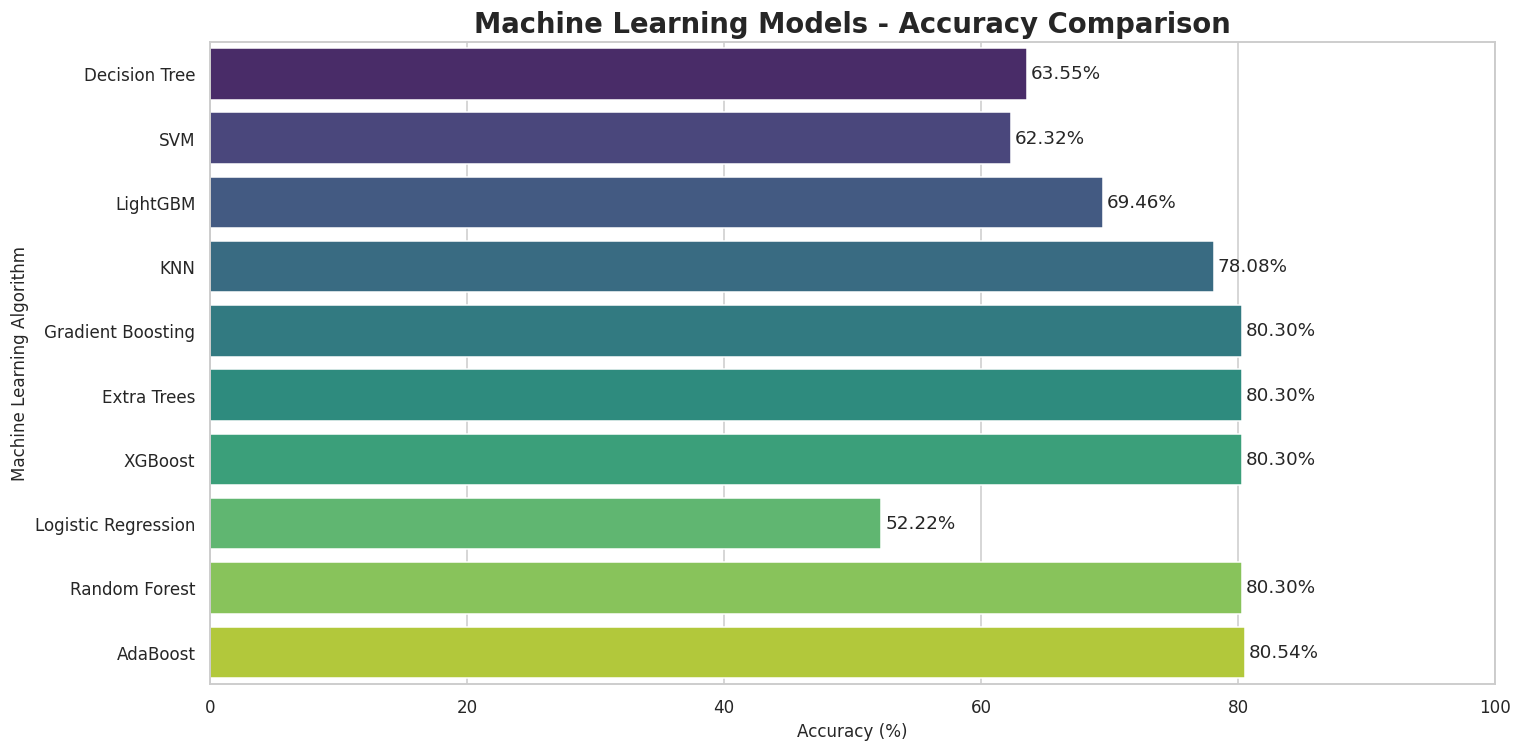

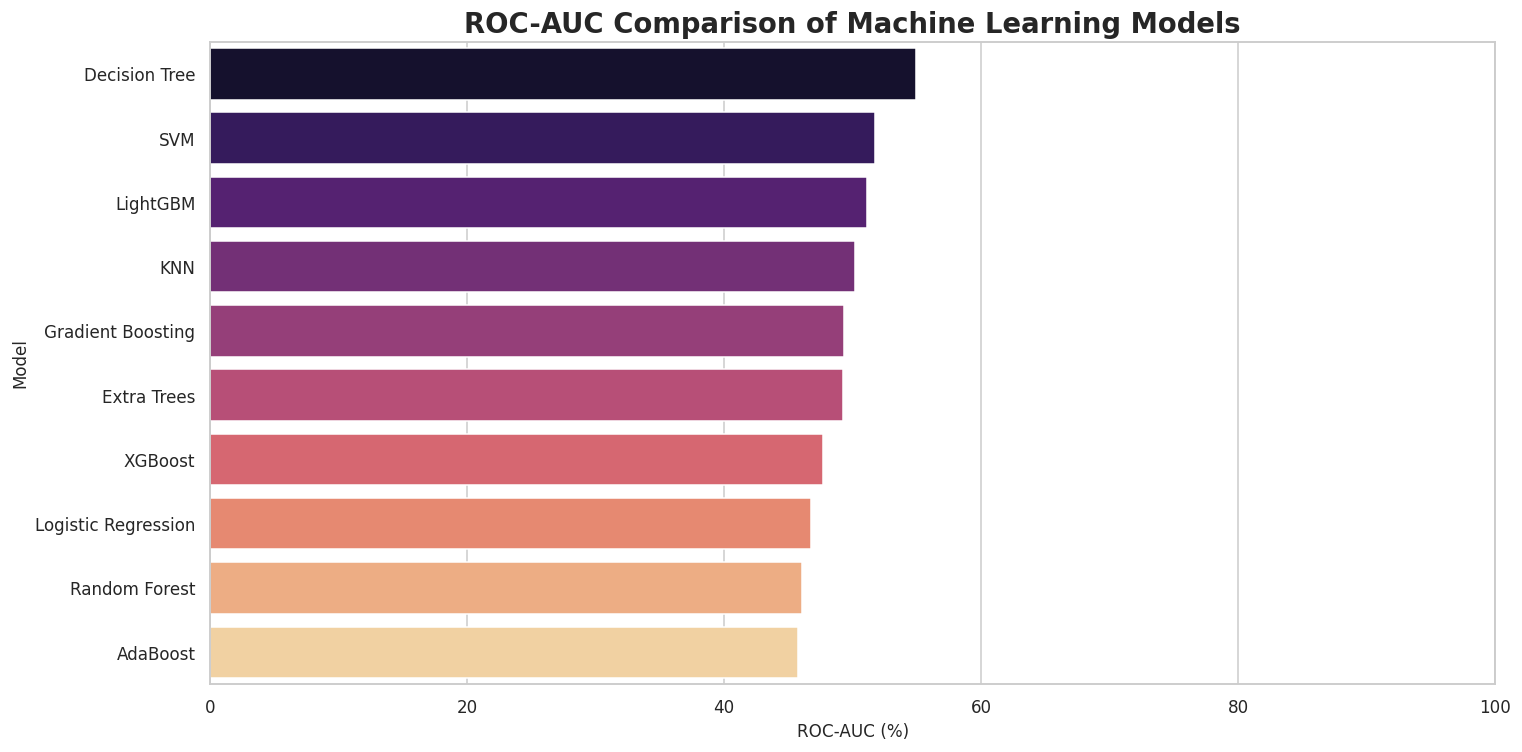

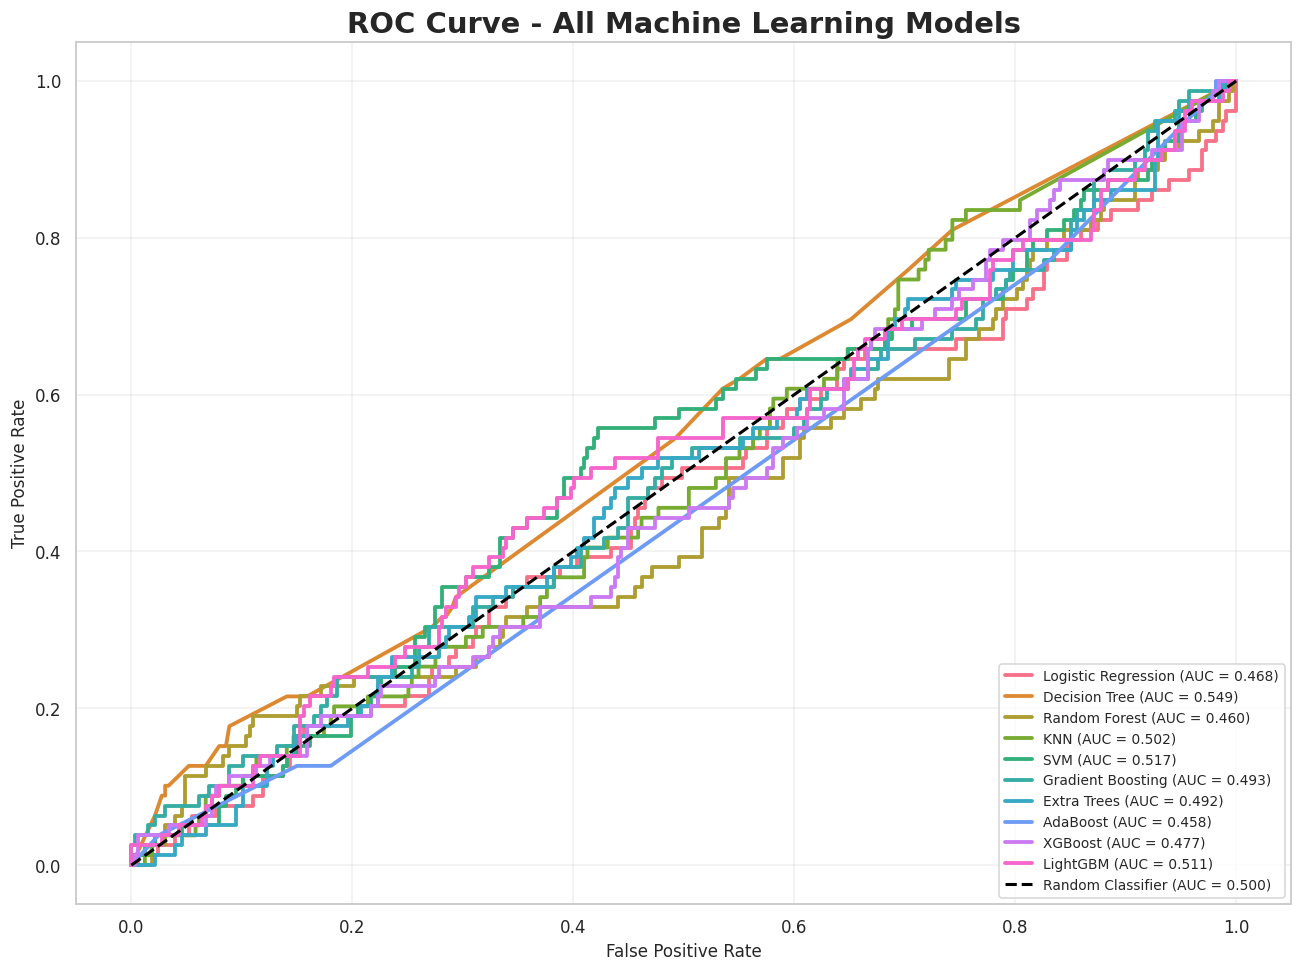

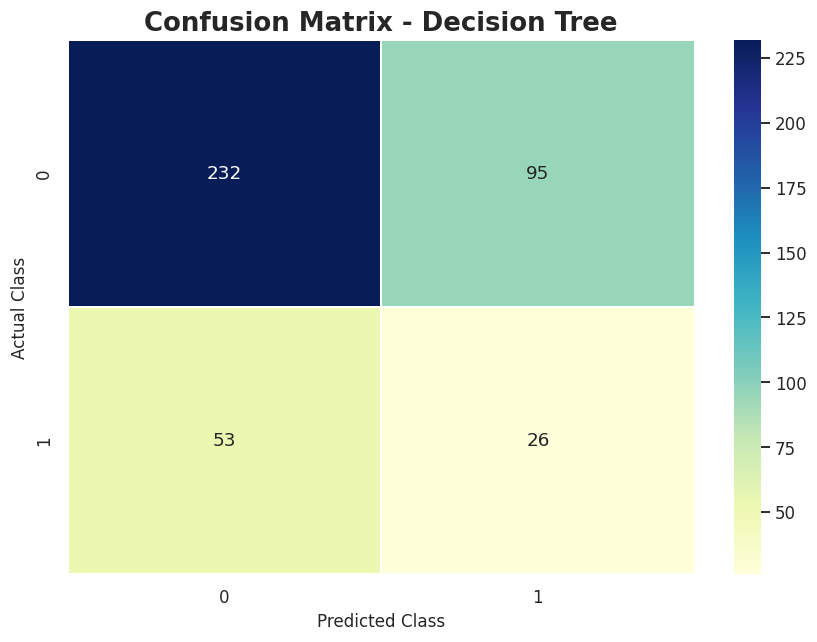


BEST MODEL: Decision Tree


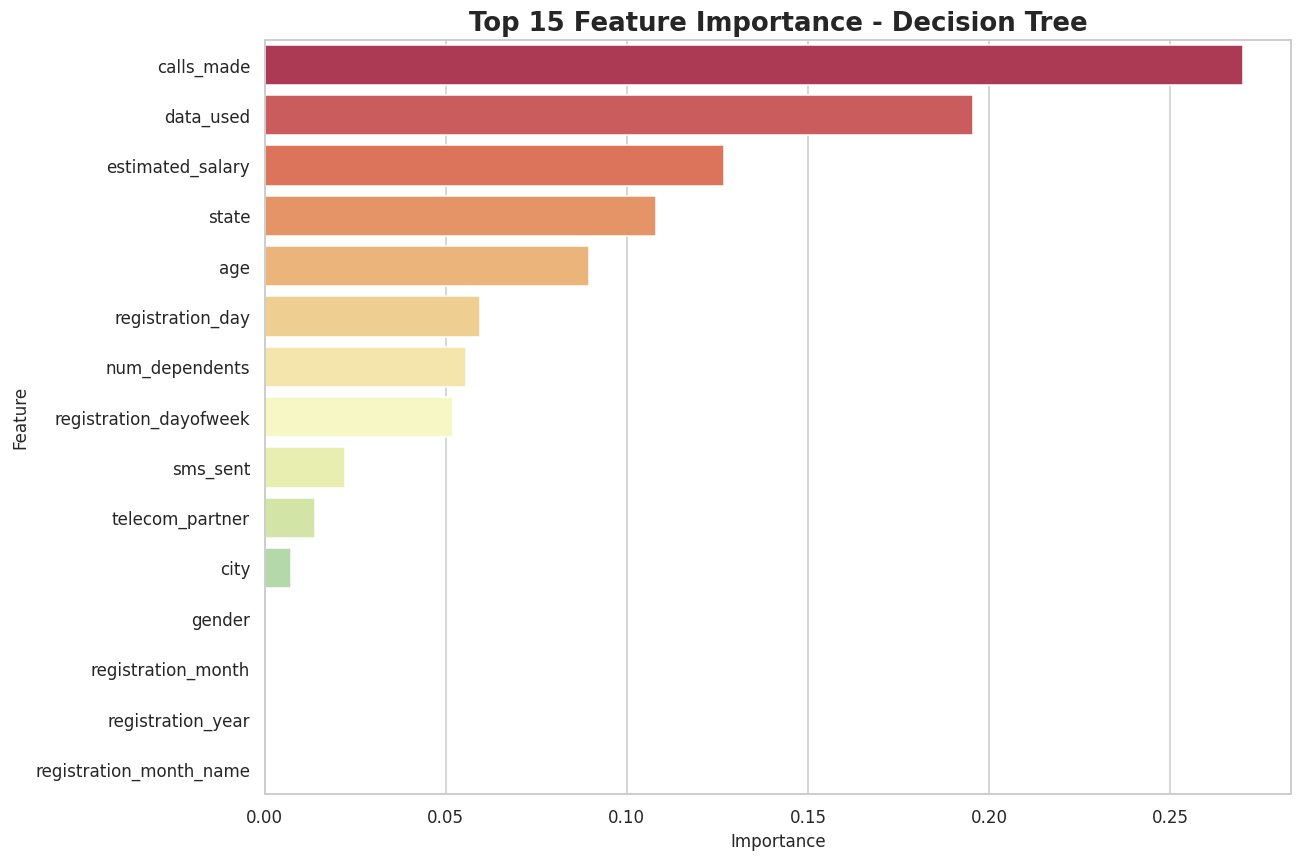

,Feature,Importance
7,calls_made,0.269908
9,data_used,0.195448
6,estimated_salary,0.126806
3,state,0.108154
2,age,0.089480
13,registration_day,0.059317
5,num_dependents,0.055488
15,registration_dayofweek,0.052033
8,sms_sent,0.022193
0,telecom_partner,0.013897



FINAL TELECOM CHURN PREDICTION RESULTS

Best Model: Decision Tree
Best Accuracy: 63.55%
Best ROC-AUC: 54.93%
Best F1 Score: 26.00%

Training Samples: 1620
Testing Samples: 406

Target Encoding:
0 = 0
1 = 1

TELECOM CUSTOMER CHURN ML PIPELINE COMPLETED!


In [14]:
# ================================================================
# TELECOM CUSTOMER CHURN PREDICTION
# COMPLETE MACHINE LEARNING PIPELINE
# ================================================================

# 1. IMPORT LIBRARIES
# ================================================================

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

from sklearn.inspection import permutation_importance

sns.set_style('whitegrid')

# ================================================================
# 2. LOAD AND INSPECT DATA
# ================================================================

df = df.copy()

print("=" * 80)
print("TELECOM CUSTOMER CHURN PREDICTION")
print("=" * 80)

print("\nDataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df['churn'].value_counts(dropna=False))

# ================================================================
# 3. DATA CLEANING
# ================================================================

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove records with missing target
df = df.dropna(subset=['churn']).copy()

# Clean categorical values
categorical_columns = [
    'telecom_partner',
    'gender',
    'state',
    'city',
    'churn'
]

for col in categorical_columns:
    df[col] = df[col].astype(str).str.strip()

# Convert date into useful numerical features
df['date_of_registration'] = pd.to_datetime(
    df['date_of_registration'],
    errors='coerce'
)

df['registration_year'] = (
    df['date_of_registration'].dt.year
)

df['registration_month'] = (
    df['date_of_registration'].dt.month
)

df['registration_day'] = (
    df['date_of_registration'].dt.day
)

df['registration_dayofweek'] = (
    df['date_of_registration'].dt.dayofweek
)

# Remove original date column
df.drop(
    columns=['date_of_registration'],
    inplace=True
)

# Convert numerical columns
numeric_columns = [
    'age',
    'num_dependents',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used',
    'pincode',
    'registration_year',
    'registration_month',
    'registration_day',
    'registration_dayofweek'
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col], errors='coerce'
        )

# Investigate invalid negative values.
# These columns are expected to be non-negative.
nonnegative_columns = [
    'age',
    'num_dependents',
    'estimated_salary',
    'calls_made',
    'sms_sent',
    'data_used',
    'pincode'
]

print("\nNegative Value Analysis:")

for col in nonnegative_columns:
    if col in df.columns:
        count = (df[col] < 0).sum()
        print(f"{col}: {count} negative values")

        # Treat impossible negative values as missing.
        # Median imputation will be learned from training data.
        df.loc[df[col] < 0, col] = np.nan

# ================================================================
# 4. FEATURE SELECTION
# ================================================================

# Target variable
target = 'churn'

# Remove customer_id because it is an identifier,
# not a meaningful customer behavior feature.
# Remove pincode to avoid high-cardinality location noise.
# City and state are retained as categorical features.

drop_columns = [
    'customer_id',
    'pincode'
]

X = df.drop(
    columns=[target] + drop_columns,
    errors='ignore'
)

y = df[target].copy()

print("\nSelected Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.value_counts())

# Ensure binary classification
if y.nunique() != 2:
    raise ValueError(
        f"Expected binary churn target, but found {y.nunique()} classes: "
        f"{y.unique()}"
    )

# ================================================================
# 5. TRAIN-TEST SPLITTING
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

# ================================================================
# 6. LABEL ENCODING
# ================================================================

# Encode target variable
target_encoder = LabelEncoder()

y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

print("\nTarget Label Mapping:")

for i, label in enumerate(target_encoder.classes_):
    print(f"{label} = {i}")

# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

# Label encode each categorical feature.
# Fit encoders ONLY on training data.
# Unseen testing categories receive -1.

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

label_encoders = {}

for col in categorical_features:

    encoder = LabelEncoder()

    train_values = (
        X_train_processed[col]
        .fillna('Missing')
        .astype(str)
    )

    test_values = (
        X_test_processed[col]
        .fillna('Missing')
        .astype(str)
    )

    X_train_processed[col] = encoder.fit_transform(
        train_values
    )

    known_classes = set(encoder.classes_)

    X_test_processed[col] = test_values.apply(
        lambda value: (
            int(encoder.transform([value])[0])
            if value in known_classes
            else -1
        )
    )

    label_encoders[col] = encoder

# ================================================================
# 7. MISSING VALUE HANDLING
# ================================================================

# Learn medians from training data only
imputer = SimpleImputer(strategy='median')

X_train_processed = pd.DataFrame(
    imputer.fit_transform(X_train_processed),
    columns=X.columns,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    imputer.transform(X_test_processed),
    columns=X.columns,
    index=X_test.index
)

# ================================================================
# 8. FEATURE SCALING
# ================================================================

# Fit scaler using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_processed
)

X_test_scaled = scaler.transform(
    X_test_processed
)

print("\nPreprocessing Completed Successfully!")

print("Training Data:", X_train_scaled.shape)
print("Testing Data:", X_test_scaled.shape)

# ================================================================
# 9. DEFINE MACHINE LEARNING MODELS
# ================================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    ),

    'SVM': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

# Add XGBoost if installed
try:
    from xgboost import XGBClassifier

    models['XGBoost'] = XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("\nXGBoost not installed. Skipping XGBoost.")

# Add LightGBM if installed
try:
    from lightgbm import LGBMClassifier

    models['LightGBM'] = LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=7,
        class_weight='balanced',
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("\nLightGBM not installed. Skipping LightGBM.")

print("\nModels Selected:")
for name in models:
    print("-", name)

# ================================================================
# 10. MODEL TRAINING AND EVALUATION
# ================================================================

results = []
trained_models = {}
roc_predictions = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print("TRAINING:", name)
    print("=" * 70)

    try:

        # Distance-based and margin-based models use scaled features.
        # Tree models use the original imputed features.
        if name in [
            'Logistic Regression',
            'KNN',
            'SVM'
        ]:
            Xtr = X_train_scaled
            Xte = X_test_scaled
        else:
            Xtr = X_train_processed
            Xte = X_test_processed

        # Train
        model.fit(Xtr, y_train_encoded)

        # Predict
        y_pred = model.predict(Xte)

        # Positive-class probabilities for ROC
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(Xte)[:, 1]

        elif hasattr(model, 'decision_function'):
            y_prob = model.decision_function(Xte)

        else:
            raise ValueError(
                "Model does not support ROC scoring."
            )

        # Evaluation metrics
        accuracy = accuracy_score(
            y_test_encoded, y_pred
        )

        precision = precision_score(
            y_test_encoded, y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test_encoded, y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test_encoded, y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test_encoded, y_prob
        )

        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC-AUC': auc * 100
        })

        trained_models[name] = model
        roc_predictions[name] = y_prob

        print(f"\nAccuracy  : {accuracy * 100:.2f}%")
        print(f"Precision : {precision * 100:.2f}%")
        print(f"Recall    : {recall * 100:.2f}%")
        print(f"F1 Score  : {f1 * 100:.2f}%")
        print(f"ROC-AUC   : {auc * 100:.2f}%")

        print("\nClassification Report:")
        print(
            classification_report(
                y_test_encoded,
                y_pred,
                target_names=[
                    str(c) for c in target_encoder.classes_
                ],
                zero_division=0
            )
        )

    except Exception as e:

        print(f"Model failed: {name}")
        print("Error:", str(e))

# ================================================================
# 11. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError(
        "All models failed. Check your dataset and preprocessing."
    )

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("MACHINE LEARNING MODEL COMPARISON")
print("=" * 80)

display(
    results_df.style
    .format({
        'Accuracy': '{:.2f}%',
        'Precision': '{:.2f}%',
        'Recall': '{:.2f}%',
        'F1 Score': '{:.2f}%',
        'ROC-AUC': '{:.2f}%'
    })
    .background_gradient(cmap='YlGnBu')
)

# ================================================================
# 12. MODEL ACCURACY COMPARISON
# ================================================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df,
    x='Accuracy',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title(
    'Machine Learning Models - Accuracy Comparison',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Accuracy (%)')
plt.ylabel('Machine Learning Algorithm')
plt.xlim(0, 100)

for i, value in enumerate(results_df['Accuracy']):
    plt.text(
        value + 0.3,
        i,
        f'{value:.2f}%',
        va='center'
    )

plt.tight_layout()
plt.show()

# ================================================================
# 13. ROC-AUC COMPARISON
# ================================================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df.sort_values('ROC-AUC', ascending=False),
    x='ROC-AUC',
    y='Model',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title(
    'ROC-AUC Comparison of Machine Learning Models',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('ROC-AUC (%)')
plt.ylabel('Model')
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

# ================================================================
# 14. ROC CURVE FOR ALL MODELS
# ================================================================

plt.figure(figsize=(12, 9))

roc_colors = sns.color_palette(
    'husl',
    n_colors=len(roc_predictions)
)

for (name, y_prob), color in zip(
    roc_predictions.items(),
    roc_colors
):

    fpr, tpr, thresholds = roc_curve(
        y_test_encoded,
        y_prob
    )

    auc_value = roc_auc_score(
        y_test_encoded,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        color=color,
        label=f'{name} (AUC = {auc_value:.3f})'
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    linewidth=2,
    label='Random Classifier (AUC = 0.500)'
)

plt.title(
    'ROC Curve - All Machine Learning Models',
    fontsize=19,
    fontweight='bold'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 15. CONFUSION MATRIX - BEST MODEL
# ================================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

if best_model_name in [
    'Logistic Regression',
    'KNN',
    'SVM'
]:
    X_best = X_test_scaled
else:
    X_best = X_test_processed

best_predictions = best_model.predict(X_best)

cm = confusion_matrix(
    y_test_encoded,
    best_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=1,
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title(
    f'Confusion Matrix - {best_model_name}',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

# ================================================================
# 16. FEATURE IMPORTANCE
# ================================================================

print("\nBEST MODEL:", best_model_name)

if hasattr(best_model, 'feature_importances_'):

    importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_model.feature_importances_
    })

    importance = importance.sort_values(
        by='Importance',
        ascending=False
    )

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance.head(15),
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='Spectral',
        legend=False
    )

    plt.title(
        f'Top 15 Feature Importance - {best_model_name}',
        fontsize=17
    )

    plt.tight_layout()
    plt.show()

    display(importance)

else:

    print(
        "Calculating permutation importance for the best model..."
    )

    permutation = permutation_importance(
        best_model,
        X_best,
        y_test_encoded,
        n_repeats=5,
        random_state=42,
        scoring='roc_auc',
        n_jobs=-1
    )

    importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': permutation.importances_mean
    }).sort_values(
        by='Importance',
        ascending=False
    )

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance.head(15),
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='coolwarm',
        legend=False
    )

    plt.title(
        f'Permutation Feature Importance - {best_model_name}',
        fontsize=17
    )

    plt.tight_layout()
    plt.show()

    display(importance)

# ================================================================
# 17. FINAL MODEL SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("FINAL TELECOM CHURN PREDICTION RESULTS")
print("=" * 80)

print("\nBest Model:", best_model_name)

print(
    "Best Accuracy:",
    f"{results_df.iloc[0]['Accuracy']:.2f}%"
)

print(
    "Best ROC-AUC:",
    f"{results_df.iloc[0]['ROC-AUC']:.2f}%"
)

print(
    "Best F1 Score:",
    f"{results_df.iloc[0]['F1 Score']:.2f}%"
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTarget Encoding:")

for i, label in enumerate(target_encoder.classes_):
    print(f"{label} = {i}")

print("\n" + "=" * 80)
print("TELECOM CUSTOMER CHURN ML PIPELINE COMPLETED!")
print("=" * 80)

## Thank you..pls upvote!!!!!!!!!!!!